# 32i quantification — SlideTags dataset

Same method as `quantify_32i.ipynb` (NucSeq), adapted to the SlideTags dataset.

Main differences w.r.t. the NucSeq version:
- each library = **one donor** (no multiplexing, no donor-id remapping) → donor metadata is already in `obs`
- library/BAM paths come from `XDP Slidetags - CellBender Terra table - cb.csv` (`bam_folder_path`)
- cell barcode join key = `library_id` + `original_barcode` (BAM `CB` tag already has the `-1` suffix)
- `X` in the h5ad is empty → raw counts live in `layers["counts"]`; the file is 46 GB, and `backed="r"` would still load `layers` in RAM → `obs` and the TAF1 column are read directly with `h5py`
- condition labels `healthy` / `diseased` → remapped to `Control` / `XDP` so the plotting code is the same
- cell type names differ (`Oligo`, `Astro`, ...)
- covariates (age of death / onset, repeat length) come from `obs`, not from the NucSeq metadata csv
- extra SlideTags-only section: 32i in **dead vs healthy tissue region** within XDP donors
- reads are split by strand (**sense** vs **antisense** to TAF1) → every analysis is a function, run on both versions of the 32i metric (`METRICS`)
- `EXCLUDE_DONORS`: donors removed from the analyses (not from the quantification) → outputs get an `_excl_...` suffix

Requires `samtools` + `gcloud` (see install notes in `quantify_32i.ipynb`).

In [1]:
import pysam
import h5py
import pandas as pd
from collections import defaultdict
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt
import subprocess
import numpy as np
from anndata.io import read_elem

In [2]:
TAF1_START_END = "71366357-71466005" # refseq igv
TAF1_START_END_W = "71366000-71467000" # bigger window arounf TAF1 to extrast subset of bam
TAF1_EXON32_START_END = "71424154-71424238" # refseq igv
TAF1_INTRON32_START_END = "71424239-71454169" # refseq igv
TAF1_EXON33_START_END = "71454170-71454237" # refseq igv

EXON32_LAST_BP    = int(TAF1_EXON32_START_END.split("-")[1])
INTRON32_FIRST_BP = int(TAF1_INTRON32_START_END.split("-")[0])
INTRON32_LAST_BP  = int(TAF1_INTRON32_START_END.split("-")[1])
EXON33_START_BP   = int(TAF1_EXON33_START_END.split("-")[0])
EXON33_END_BP     = int(TAF1_EXON33_START_END.split("-")[1])
EXON38_END_BP     = int(TAF1_START_END.split("-")[1])
INTRON_LENGHT     = int(INTRON32_LAST_BP) - int(EXON32_LAST_BP) #29931
SVA_START_BP       = 71440512   # published start of the SVA insertion (= end of "pre" / 32i region)

TAF1_EXON32_INTRON32_JUNCTION_W = f"{int(EXON32_LAST_BP)-9}-{int(INTRON32_FIRST_BP)+9}" # 71424228-71424249

INTRON_LENGHT
TAF1_EXON32_INTRON32_JUNCTION_W

'71424229-71424248'

# SlideTags Data

Each library contains a single donor (a donor has several libraries, Unsorted + NeuN+)

In [3]:
ADATA_PATH    = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad"
LIB_META_PATH = "/home/gdallagl/myworkdir/XDP/utils/SlideTags_XDP_metadata/XDP Slidetags - CellBender Terra table - cb.csv"
BAM_LOCAL_DIR = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/SlideTags_single_libraries"  # {sample}/{bcl}/{RNAindex}/bam
OUT_DIR       = Path("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/32i")
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET = "SlideTags"

# donors removed from the ANALYSES (pseudobulk onwards), not from the 32i quantification:
# the per-cell csv and the per-library strand plots still have all donors
# donor_id or donor_number, e.g. ["SCF-18-006"] / ["sample_09"] (paired-end run, see strand notes)
EXCLUDE_DONORS = ["SCF-18-006"] #donro ) fue to piared end
# used in output file names and plot titles, so runs with/without exclusion do not overwrite each other
ANALYSIS_NAME = DATASET + ("_excl_" + "_".join(EXCLUDE_DONORS) if EXCLUDE_DONORS else "")

In [4]:
# Use the barcodes in processed adata
# read only obs (backed="r" would load the 36 GB counts layer in memory)
with h5py.File(ADATA_PATH, "r") as f:
    obs_st = read_elem(f["obs"])
    var_st = read_elem(f["var"])
obs_st["obs_idx"] = np.arange(len(obs_st))  # row position in the h5ad, needed later to read TAF1 counts

# remvoe bad quality cells ("-Low_quality", "-TAFA1") and leftover "tmp" label
# obs_st = obs_st[~obs_st["ct_for_deg"].astype(str).str.startswith("-") & (obs_st["ct_for_deg"] != "tmp")]

# merge cell types
obs_st["ct_for_deg"] = (
    obs_st["ct_for_deg"]
    .astype(str)
    .replace({
        "Matrix_D1": "Matrix",
        "Matrix_D2": "Matrix",
        "Patch_D1": "Patch",
        "Patch_D2": "Patch"
    })
    .astype("category")
)

# same condition labels as NucSeq
obs_st["condition"] = (
    obs_st["condition"].astype(str)
    .map({"healthy": "Control", "diseased": "XDP"})
    .astype(pd.CategoricalDtype(["Control", "XDP"]))
)

# original_barcode is unique within a library (== CB tag in the bam)
obs_st["library_id"] = obs_st["library_id"].astype(str)
obs_st["original_barcode"] = obs_st["original_barcode"].astype(str)
assert not obs_st.duplicated(["library_id", "original_barcode"]).any()

display(obs_st)
print("number of donors in obs_st:", obs_st.groupby("donor_id", observed=True).ngroups)
display(obs_st.groupby(["donor_number", "donor_id", "condition"], observed=True).size().rename("n_cells"))

# which libs have been used for the sample in this adata
slidetags_libs = obs_st["library_id"].unique().tolist()
len(slidetags_libs)

,x,y,pct_intronic,dbscan_clusters,dbscan_score,has_spatial,sample,Neighborhood_name,Neighborhood_bootstrapping_probability,Neighborhood_aggregate_probability,...,zone_4_probability,leiden_0.1_all_cells,leiden_0.5_all_cells,leiden_0.07_all_cells,tmp_label,ct_for_deg,puck,region,image,obs_idx
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1,33013.428400,444.562211,0.585746,3.0,0.230731,False,sample_01,Nonneuron,1.00,1.00,...,0.755,0,0,0,Astro,Astro,NaN,NaN,sample_01_<NA>,0
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGCATGGAG-1,21225.159553,4193.340108,0.596834,1.0,0.942997,True,sample_01,Nonneuron,1.00,1.00,...,NaN,5,6,2,Microglia,Microglia,puck1,healthy,sample_01_puck1,1
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGCGGAGT-1,16429.015488,3852.143369,0.716821,1.0,0.936590,True,sample_01,Nonneuron,1.00,1.00,...,NaN,6,7,1,Oligo,Oligo,puck1,dead,sample_01_puck1,2
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTCTATG-1,43242.438818,-1822.457007,0.609493,0.0,0.366933,False,sample_01,Nonneuron,1.00,1.00,...,0.855,0,0,0,Astro,Astro,NaN,NaN,sample_01_<NA>,3
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTTGTAT-1,14118.369028,-4852.270550,0.588186,1.0,0.859807,True,sample_01,Nonneuron,1.00,1.00,...,NaN,6,3,1,Oligo,Oligo,puck1,healthy,sample_01_puck1,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTCTTCGTTCTAC-1,35002.539607,-2215.668368,0.759874,1.0,0.996100,True,sample_12,Subpallium GABA,0.68,0.68,...,NaN,3,9,3,non-MSN,non-MSN,puck2,healthy,sample_12_puck2,742891
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGCAGATCACAT-1,9228.794116,1053.109411,0.774319,1.0,0.995154,True,sample_12,Subpallium GABA,1.00,1.00,...,0.911,1,14,4,MSN,Patch,puck1,healthy,sample_12_puck1,742892
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGGGTACCATCC-1,26039.976024,141.914384,0.756758,1.0,0.958534,True,sample_12,Subpallium GABA,1.00,1.00,...,NaN,1,10,4,MSN,Matrix,puck1,healthy,sample_12_puck1,742893
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H3---GTTGTGGGTCATACTT-1,47745.124273,-9436.079408,0.743346,7.0,0.290273,False,sample_12,Subpallium GABA,1.00,1.00,...,NaN,1,10,4,MSN,-Low_quality,NaN,NaN,sample_12_<NA>,742894


number of donors in obs_st: 12


donor_number  donor_id    condition
sample_01     SCF-18-003  XDP           95409
sample_02     SCF-20-025  XDP           41852
sample_03     SCF-19-014  XDP           39648
sample_04     SCF-20-024  XDP           35378
sample_05     SCF-23-068  Control       34426
sample_06     SCF-20-026  XDP           36870
sample_07     SCF-22-057  Control       27228
sample_08     SCF-22-043  XDP          146631
sample_09     SCF-18-006  XDP          131788
sample_10     SCF-21-032  XDP           51560
sample_11     SCF-23-075  Control       53621
sample_12     SCF-22-065  Control       48485
Name: n_cells, dtype: int64

51

In [5]:
# read here from where the .bam file are located
df_lib_st = pd.read_csv(LIB_META_PATH)

# libraries in the table but not in the adata (dropped during QC)
print("not in adata:", sorted(set(df_lib_st["entity:library_id"]) - set(slidetags_libs)))
assert set(slidetags_libs) <= set(df_lib_st["entity:library_id"])

# select only the libraries that are in the slidetags_libs list
df_lib_st = df_lib_st[df_lib_st["entity:library_id"].isin(slidetags_libs)]

df_lib_st[["entity:library_id", "donor_number", "donor_id", "condition", "bcl", "RNAindex", "Sorted", "bam_folder_path"]]

not in adata: ['260629_SL-EXP_0408_A23TTYKLT4_SI-TT-B1', '260629_SL-EXP_0408_A23TTYKLT4_lane78_SI-TT-B2', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H4', '260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H6']


,entity:library_id,donor_number,donor_id,condition,bcl,RNAindex,Sorted,bam_folder_path
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H1,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H2,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3,sample_01,SCF-18-003,diseased,251027_SL-EXD_0706_A233KGFLT4,SI-TT-H3,NeUN+,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
3,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B10,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
4,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B11,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
5,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-B12,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
6,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1,sample_02,SCF-20-025,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C1,NeUN+,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
7,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C2,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
8,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C3,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...
9,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4,sample_03,SCF-19-014,diseased,260313_SL-EXA_0758_B23GHNHLT4,SI-TT-C4,Unsorted,gs://fc-secure-d99fbd65-eb27-4989-95b4-4cf559a...


# Calcualte 32i 

*) Read
- blocks: a block is a tuple (start, end) that tell in the genome where a subset of the read have been aligned
    - ex. a read of a spliced rna will have 2 blocks (i, endexon 1), (start exon 2, j)

- cigartuple: list of (operation, length) (one for each block), that tell how the read bases in that blcok have been aligned

In [6]:
def overlaps_window(read, win_start, win_end):
    # checks whether any aligned block of a read overlaps [win_start, win_end]

    # attetion, need to conver base 0
    win_start0, win_end0 = win_start - 1, win_end - 1
    for block_start, block_end in read.get_blocks():
        if block_start < win_end0 and block_end > win_start0:
            return True
    return False

def has_canonical_splice(read, gap):
    #returns True if the read contains a splice gap of exactly 29,931 bp 
    # the canonical exon32→exon33 intron length
    if read.cigartuples is None:
        return False
    # attention op=3 encode "N" (skipped region from the reference)
    return any(op == 3 and length == gap for op, length in read.cigartuples)

**Strand**: TAF1 is a + strand gene, but in these BAMs TAF1 mRNA reads map on the **reverse** strand (sense = reverse).
sample_09 libraries are aligned paired-end → read1 orientation is flipped (see `fragment_is_reverse`).

In [7]:
PRE_START, PRE_END   = INTRON32_FIRST_BP, SVA_START_BP     # 32i intron pile-up region
POST_START, POST_END = EXON33_START_BP, int(TAF1_START_END.split("-")[1])     # downstream normal transcript
CANONICAL_SPLICE_LEN = EXON33_START_BP - EXON32_LAST_BP - 1   # 29931

# if False, reuse taf1_subset.bam already on disk
# (keep True if the cell list in the adata changed -- old subsets were filtered with all_lib_adata.h5ad barcodes)
OVERWRITE_BAM = True

# STRAND
# TAF1 is a + strand gene, but in these BAMs TAF1 mRNA reads map on the REVERSE strand
# (~98% of exon33-38 reads are reverse; Cell Ranger tags them GN=TAF1, the forward ones AN=TAF1 = antisense)
# sample_09 libraries (240911 run) are aligned PAIRED-END: read1 and read2 of the same molecule map on
# opposite strands -> read1 orientation is flipped, so every read reports the orientation of read2
# -> do not assume: per library, sense = majority orientation of the reads in the exonic POST window
def fragment_is_reverse(read):
    return read.is_reverse != read.is_read1

per_cell_results = []   # one row per (library, cell)
lib_strand_qc = []      # one row per library, orientation check

for _, row in df_lib_st.iterrows():

    # select the library --> so we can take the relative BAM
    library_id, sample, bcl, rna_index = row["entity:library_id"], row["donor_number"], row["bcl"], row["RNAindex"]
    print(library_id)

    # where to save bam file locally
    save_folder = Path(f"{BAM_LOCAL_DIR}/{sample}/{bcl}/{rna_index}/bam")
    save_folder.mkdir(parents=True, exist_ok=True)
    subset_bam_path = save_folder / "taf1_subset.bam"
    # where is the file in the cloud (GCP bucket)
    bam = f"{row['bam_folder_path'].rstrip('/')}/possorted_genome_bam.bam"

    # called cells for this library from curated adata
    CALLED_CELLS = set(obs_st.loc[obs_st["library_id"] == library_id, "original_barcode"])
    # save this barcodes (one file per library)
    BC_FILE = save_folder / "called_cells.txt"
    with open(BC_FILE, "w") as f:
        for cell in CALLED_CELLS:
            f.write(f"{cell}\n")

    script = f"""
        set -e

        export GCS_OAUTH_TOKEN=$(gcloud auth print-access-token)

        BAM="{bam}"
        cd "{save_folder}"

        # view --> subset
        # -b --> ouput bam
        # -q 30 --> only reads with MAPQ >= 30
        # -F 0x904 --> exclude unmapped, secondary, supplementary reads
        # -D CB:"{BC_FILE}" --> only reads with CB in the list of barcodes in the file
        # chrX:{TAF1_START_END_W} --> only reads mapping to chrX in the TAF1 region
        samtools view \\
          -b \\
          -q 30 -F 0x904 \\
          -D CB:"{BC_FILE}" \\
          "$BAM" \\
          chrX:{TAF1_START_END_W} \\
          -o taf1_subset.bam
        
        # name .bai
        samtools index taf1_subset.bam
    """

    # Run the scirpt
    # reading from GCS can fail randomly ("Illegal seek") -> retry
    if OVERWRITE_BAM or not subset_bam_path.exists():
        for attempt in range(3):
            proc = subprocess.run(["bash", "-c", script], capture_output=True, text=True)
            if proc.returncode == 0:
                break
            print(f"attempt {attempt + 1} failed: {library_id}\n{proc.stderr}")
        else:
            print(f"FAILED (subset step): {library_id}")
            continue

    # -----------------------------------------------------------------
    # UMI counting, PER CELL -- dict of CB -> set of UMIs
    # -----------------------------------------------------------------

    # create a on obj from the bam file to query
    bam_fh = pysam.AlignmentFile(str(subset_bam_path), "rb") # needs .bai in same folder

    # dict[(window, fragment_is_reverse)][cell] = {set of UMIs} --> set allow deduplication of UMIs
    # orientation is converted to sense/antisense after the POST window tells which one is sense
    umis = {(win, is_rev): defaultdict(set) for win in ("pre", "post") for is_rev in (False, True)}

    # seach for reads falling in PRE
    for read in bam_fh.fetch("chrX", PRE_START, PRE_END):

        # if read in bad qulity, skip it
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue

        # CB = cell barcode, UB = UMI barcode (Tags from cell ranger)
        if not (read.has_tag("CB") and read.has_tag("UB")):
            continue

        #  read have an actual aligned base — not just span — physically inside [PRE_START, PRE_END]
        if not overlaps_window(read, PRE_START, PRE_END):
            continue

        # exclude normal exon32→33 spliced reads that touch the pre-window edge
        if has_canonical_splice(read, gap=CANONICAL_SPLICE_LEN):
            continue  # normal spliced transcript, not 32i pile-up

        umis[("pre", fragment_is_reverse(read))][read.get_tag("CB")].add(read.get_tag("UB"))

    # seach for reads falling in POST (no splice filter)
    for read in bam_fh.fetch("chrX", POST_START, POST_END):
        if read.is_unmapped or read.is_secondary or read.is_supplementary:
            continue
        if not (read.has_tag("CB") and read.has_tag("UB")):
            continue
        if not overlaps_window(read, POST_START, POST_END):
            continue
        umis[("post", fragment_is_reverse(read))][read.get_tag("CB")].add(read.get_tag("UB"))

    # close the obj
    bam_fh.close()

    # sense orientation = majority orientation of exonic (POST) UMIs in this library
    n_post_rev = sum(len(u) for u in umis[("post", True)].values())
    n_post_fwd = sum(len(u) for u in umis[("post", False)].values())
    sense_is_reverse = n_post_rev > n_post_fwd
    lib_strand_qc.append({
        "library_id": library_id,
        "n_post_umis_reverse": n_post_rev,
        "n_post_umis_forward": n_post_fwd,
        "frac_post_reverse": n_post_rev / (n_post_rev + n_post_fwd) if (n_post_rev + n_post_fwd) else np.nan,
        "sense_is_reverse": sense_is_reverse,
    })
    # (window, strand) -> per cell UMIs
    umis = {(win, "sense" if is_rev == sense_is_reverse else "antisense"): d for (win, is_rev), d in umis.items()}

    # one row per called cell with any pre/post coverage (zeros filled after merging onto obs)
    for cb in set().union(*umis.values()):
        rec = {"original_barcode": cb, "library_id": library_id}
        for win in ("pre", "post"):
            sense, antisense = umis[(win, "sense")].get(cb, set()), umis[(win, "antisense")].get(cb, set())
            rec[f"n_{win}_umis"] = len(sense | antisense)   # both strands, same as before the split
            rec[f"n_{win}_sense_umis"] = len(sense)
            rec[f"n_{win}_antisense_umis"] = len(antisense)
        per_cell_results.append(rec)

# df_cell_metrics_st only has a row for a cell if it had at least one qualifying read in the pre- or post-window
df_cell_metrics_st = pd.DataFrame(per_cell_results)

# orientation check: frac_post_reverse should be close to 0 or 1 in every library
df_lib_strand_qc = pd.DataFrame(lib_strand_qc)
display(df_lib_strand_qc)
ambiguous = df_lib_strand_qc[df_lib_strand_qc["frac_post_reverse"].between(0.2, 0.8)]
if len(ambiguous):
    print("WARNING - libraries without a clear strand orientation:", ambiguous["library_id"].tolist())
print("sense = reverse strand in", df_lib_strand_qc["sense_is_reverse"].sum(), "/", len(df_lib_strand_qc), "libraries")

df_cell_metrics_st

251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1


251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2
251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C5
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C6
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C7
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C8
260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D7
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D8
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-D9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E7
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E8
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E9
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E10
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E11
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-E12
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-F7
260415_SL-EXF_0678_B23K5JWLT4_SI-TT-F8
260415_SL-EXF_0678_

,library_id,n_post_umis_reverse,n_post_umis_forward,frac_post_reverse,sense_is_reverse
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,6268,163,0.974654,True
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H2,6056,162,0.973947,True
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H3,8489,163,0.981160,True
3,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B10,3476,73,0.979431,True
4,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B11,2489,61,0.976078,True
5,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-B12,2223,56,0.975428,True
6,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C1,6512,186,0.972231,True
7,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C2,3461,378,0.901537,True
8,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C3,1418,88,0.941567,True
9,260313_SL-EXA_0758_B23GHNHLT4_SI-TT-C4,849,49,0.945434,True


sense = reverse strand in 51 / 51 libraries


,original_barcode,library_id,n_pre_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_umis,n_post_sense_umis,n_post_antisense_umis
0,GTGAGGTCAGCACCTA-1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,1,1,0,1,1,0
1,CATGTCGCAGTCGCAC-1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,2,1,1,1,1,0
2,AGACGCAAGCGTAGCT-1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,0,0,0,1,1,0
3,ACTCGGGTCGGAGGTA-1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,1,1,0,1,0,1
4,ATCGATTAGACTACAT-1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,3,3,0,0,0,0
...,...,...,...,...,...,...,...,...
256390,AATCCGTCAAGCTGCC-1,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,2,1,1,3,3,0
256391,GTCCGTACACACAATC-1,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,0,0,0,2,2,0
256392,CGTCTATTCCTTGTAC-1,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,0,0,0,1,1,0
256393,CAGGGGTAGGTATTGT-1,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,0,0,0,2,2,0


In [8]:
# Create PER cell df

COUNT_COLS = [
    "n_pre_umis", "n_post_umis",                       # both strands
    "n_pre_sense_umis", "n_pre_antisense_umis",
    "n_post_sense_umis", "n_post_antisense_umis",
]

pre_width = int(SVA_START_BP) - int(INTRON32_FIRST_BP)
post_width = int(POST_END) - int(POST_START)   # must match the window n_post_umis was counted over

def add_32i_metrics(df):
    # both strands (same metric as before the strand split)
    df["pileup_metric"] = df["n_pre_umis"] / (df["n_pre_umis"] + df["n_post_umis"])
    # ratio normalized by the width of the pre/post windows
    df["pre_density"] = df["n_pre_umis"] / pre_width
    df["post_density"] = df["n_post_umis"] / post_width
    df["pileup_metric_norm"] = df["pre_density"] / (df["pre_density"] + df["post_density"])

    # 32i ratio per strand, each strand only with itself: reads in intron 32 vs reads in exon 33-38
    # sense: TAF1 transcript stopping in intron 32 vs TAF1 mRNA downstream
    df["pileup_metric_sense"] = df["n_pre_sense_umis"] / (df["n_pre_sense_umis"] + df["n_post_sense_umis"])
    # antisense: antisense reads in intron 32 vs antisense reads in exon 33-38
    df["pileup_metric_antisense"] = df["n_pre_antisense_umis"] / (df["n_pre_antisense_umis"] + df["n_post_antisense_umis"])

    # share of the reads that are antisense, per window (compares the 2 strands within the same window)
    df["pre_antisense_fraction"] = df["n_pre_antisense_umis"] / (df["n_pre_antisense_umis"] + df["n_pre_sense_umis"])
    df["post_antisense_fraction"] = df["n_post_antisense_umis"] / (df["n_post_antisense_umis"] + df["n_post_sense_umis"])
    return df

# subset
obs_st_sub = obs_st[["library_id", "original_barcode", "condition", "ct_for_deg", "donor_id", "donor_number", "Sorted", "region", "puck"]].copy()
# add to each cell the number of pre/post UMIs counted in the bam file
obs_st_sub = obs_st_sub.merge(df_cell_metrics_st, on=["library_id", "original_barcode"], how="left")
# fill with 0 for cells that had no reads in the pre/post windows (legitimate zero counts)
obs_st_sub[COUNT_COLS] = obs_st_sub[COUNT_COLS].fillna(0)

obs_st_sub = add_32i_metrics(obs_st_sub)

obs_st_sub.to_csv(OUT_DIR / f"32i_per_cell_{DATASET}.csv", index=False)

obs_st_sub


,library_id,original_barcode,condition,ct_for_deg,donor_id,donor_number,Sorted,region,puck,n_pre_umis,...,n_post_sense_umis,n_post_antisense_umis,pileup_metric,pre_density,post_density,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction
0,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGATAACAG-1,XDP,Astro,SCF-18-003,sample_01,Unsorted,NaN,NaN,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGCATGGAG-1,XDP,Microglia,SCF-18-003,sample_01,Unsorted,healthy,puck1,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
2,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGGCGGAGT-1,XDP,Oligo,SCF-18-003,sample_01,Unsorted,dead,puck1,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
3,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGGTCTATG-1,XDP,Astro,SCF-18-003,sample_01,Unsorted,NaN,NaN,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
4,251027_SL-EXD_0706_A233KGFLT4_SI-TT-H1,AAACCAAAGGTTGTAT-1,XDP,Oligo,SCF-18-003,sample_01,Unsorted,healthy,puck1,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
742891,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,GTTGTCTTCGTTCTAC-1,Control,non-MSN,SCF-22-065,sample_12,NeUN+,healthy,puck2,1.0,...,0.0,0.0,1.000000,0.000061,0.000000,1.000000,1.000000,NaN,0.0,NaN
742892,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,GTTGTGCAGATCACAT-1,Control,Patch,SCF-22-065,sample_12,NeUN+,healthy,puck1,0.0,...,1.0,0.0,0.000000,0.000000,0.000084,0.000000,0.000000,NaN,NaN,0.0
742893,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,GTTGTGGGTACCATCC-1,Control,Matrix,SCF-22-065,sample_12,NeUN+,healthy,puck1,0.0,...,0.0,0.0,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
742894,260721_SL-EXB_0892_B23Y3GKLT4_SI-TT-H3,GTTGTGGGTCATACTT-1,Control,-Low_quality,SCF-22-065,sample_12,NeUN+,NaN,NaN,0.0,...,6.0,0.0,0.000000,0.000000,0.000507,0.000000,0.000000,NaN,NaN,0.0


In [9]:
# create per DONOR-CT df

# remove excluded donors from everything downstream
is_excluded = obs_st_sub["donor_id"].isin(EXCLUDE_DONORS) | obs_st_sub["donor_number"].isin(EXCLUDE_DONORS)
missing = set(EXCLUDE_DONORS) - set(obs_st_sub["donor_id"]) - set(obs_st_sub["donor_number"])
assert not missing, f"EXCLUDE_DONORS not found: {missing}"
obs_st_an = obs_st_sub[~is_excluded]
print("excluded donors:", obs_st_sub.loc[is_excluded, ["donor_number", "donor_id"]].drop_duplicates().values.tolist())
print("donors in the analysis:", obs_st_an.groupby("condition", observed=True)["donor_id"].nunique().to_dict())

def pseudobulk_32i(df, group_cols):
    # sum umis in same group, then recompute the metrics on the summed counts
    pb = df.groupby(group_cols, observed=True).agg(
        **{col: (col, "sum") for col in COUNT_COLS},
        n_cells=("n_pre_umis", "size"),
    ).reset_index()
    return add_32i_metrics(pb)

cell_types = ["Matrix", "Patch", "eMSN_D1D2", "eMSN_NUDAP", "non-MSN", "Oligo", "OPC", "Astro", "Microglia"]

# condition is constant per donor -> in the groupby just to carry it along
df_pseudobulk_all = pseudobulk_32i(obs_st_an[obs_st_an["ct_for_deg"].isin(cell_types)], ["donor_id", "condition", "ct_for_deg"])
df_pseudobulk_all["ct_for_deg"] = df_pseudobulk_all["ct_for_deg"].astype(str)

df_pseudobulk_all["ct"] = df_pseudobulk_all["ct_for_deg"].map({
    "Matrix": "Neuron",
    "Patch": "Neuron",
    "eMSN_D1D2": "Neuron",
    "eMSN_NUDAP": "Neuron",
    "non-MSN": "Neuron",
    "eMSN_StrioMat": "Neuron",
    "Oligo": "Glia",
    "OPC": "Glia",
    "Astro": "Glia",
    "Microglia": "Glia"
})

df_pseudobulk_all.to_csv(OUT_DIR / f"32i_per_donor_{ANALYSIS_NAME}.csv", index=False)

display(df_pseudobulk_all)

# how much signal there is on each strand
display(df_pseudobulk_all.groupby(["condition", "ct_for_deg"], observed=True)[COUNT_COLS[2:]].sum())

excluded donors: [['sample_09', 'SCF-18-006']]
donors in the analysis: {'Control': 4, 'XDP': 7}


,donor_id,condition,ct_for_deg,n_pre_umis,n_post_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,n_cells,pileup_metric,pre_density,post_density,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction,ct
0,SCF-18-003,XDP,Astro,1750.0,1694.0,1563.0,190.0,1642.0,53.0,8573,0.508130,0.107540,0.143135,0.429002,0.487676,0.781893,0.108386,0.031268,Glia
1,SCF-18-003,XDP,Matrix,732.0,1167.0,616.0,117.0,1141.0,28.0,3431,0.385466,0.044982,0.098606,0.313274,0.350598,0.806897,0.159618,0.023952,Neuron
2,SCF-18-003,XDP,Microglia,1206.0,747.0,1065.0,144.0,722.0,25.0,6712,0.617512,0.074110,0.063118,0.540052,0.595971,0.852071,0.119107,0.033467,Glia
3,SCF-18-003,XDP,OPC,393.0,243.0,344.0,49.0,237.0,6.0,2245,0.617925,0.024150,0.020532,0.540487,0.592083,0.890909,0.124682,0.024691,Glia
4,SCF-18-003,XDP,Oligo,7284.0,5967.0,6469.0,834.0,5855.0,114.0,47008,0.549694,0.447613,0.504183,0.470283,0.524911,0.879747,0.114200,0.019099,Glia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,SCF-23-075,Control,Oligo,904.0,1338.0,829.0,75.0,1315.0,23.0,11393,0.403211,0.055552,0.113054,0.329478,0.386660,0.765306,0.082965,0.017190,Glia
95,SCF-23-075,Control,Patch,1301.0,3053.0,1100.0,203.0,2992.0,62.0,6127,0.298806,0.079948,0.257964,0.236595,0.268817,0.766038,0.155794,0.020301,Neuron
96,SCF-23-075,Control,eMSN_D1D2,254.0,596.0,226.0,28.0,581.0,15.0,1668,0.298824,0.015609,0.050359,0.236611,0.280050,0.651163,0.110236,0.025168,Neuron
97,SCF-23-075,Control,eMSN_NUDAP,112.0,230.0,95.0,17.0,226.0,4.0,693,0.327485,0.006883,0.019434,0.261531,0.295950,0.809524,0.151786,0.017391,Neuron


n_pre_sense_umis  n_pre_antisense_umis  \
condition ct_for_deg                                           
Control   Astro                 1885.0                 180.0   
          Matrix                8383.0                 891.0   
          Microglia              985.0                  66.0   
          OPC                    506.0                  40.0   
          Oligo                 6118.0                 495.0   
          Patch                 2568.0                 307.0   
          eMSN_D1D2              595.0                  39.0   
          eMSN_NUDAP             217.0                  24.0   
          non-MSN               2835.0                 256.0   
XDP       Astro                 9910.0                1029.0   
          Matrix                9746.0                1286.0   
          Microglia             5967.0                 529.0   
          OPC                   2521.0                 227.0   
          Oligo                43774.0                4031.0   
          Patch                 3935.0                 443.0   
          eMSN_D1D2             1726.0                 136.0   
          eMSN_NUDAP            2878.0                 222.0   
          non-MSN              15748.0                1510.0   

                      n_post_sense_umis  n_post_antisense_umis  
condition ct_for_deg                                            
Control   Astro                  3104.0                   67.0  
          Matrix                19043.0                  399.0  
          Microglia              1203.0                   27.0  
          OPC                     762.0                   16.0  
          Oligo                 10362.0                  152.0  
          Patch                  5876.0                  113.0  
          eMSN_D1D2              1290.0                   20.0  
          eMSN_NUDAP              527.0                    7.0  
          non-MSN                6835.0                  137.0  
XDP       Astro                 10354.0                  335.0  
          Matrix                16306.0                  514.0  
          Microglia              3637.0                  129.0  
          OPC                    1831.0                   56.0  
          Oligo                 33030.0                  716.0  
          Patch                  5833.0                  183.0  
          eMSN_D1D2              2954.0                   58.0  
          eMSN_NUDAP             5356.0                  118.0  
          non-MSN               30005.0                  867.0

# How much sense Vs antisense

NORMALISARION: out of every million RNA molecules captured from these cells, how many come from intron 32?

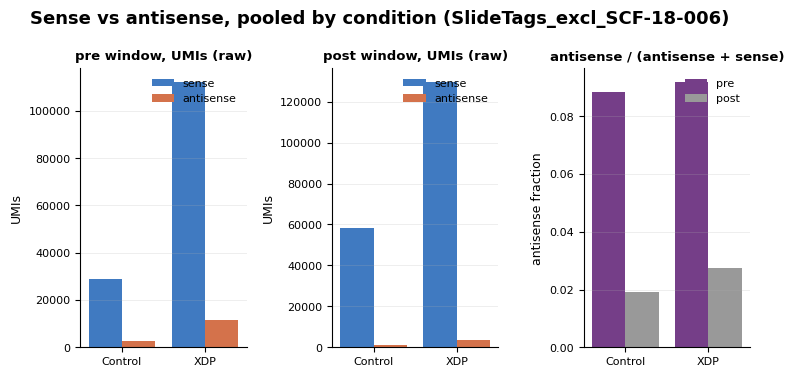

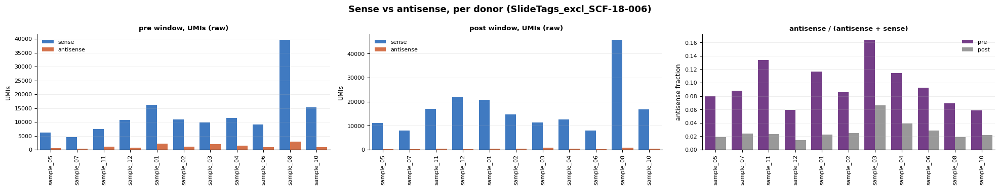

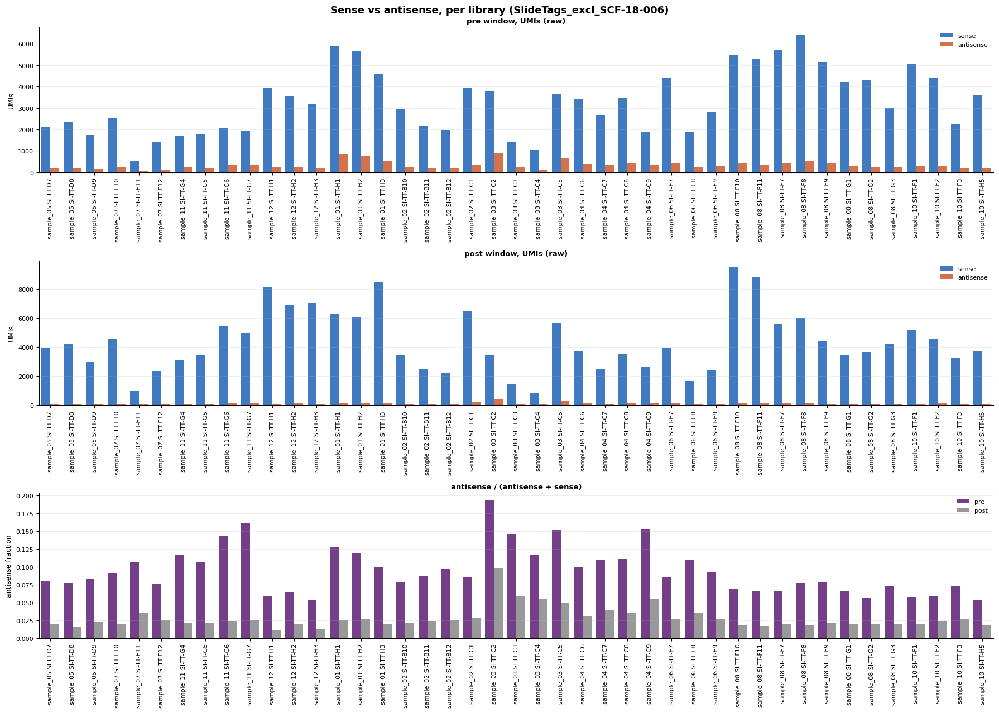

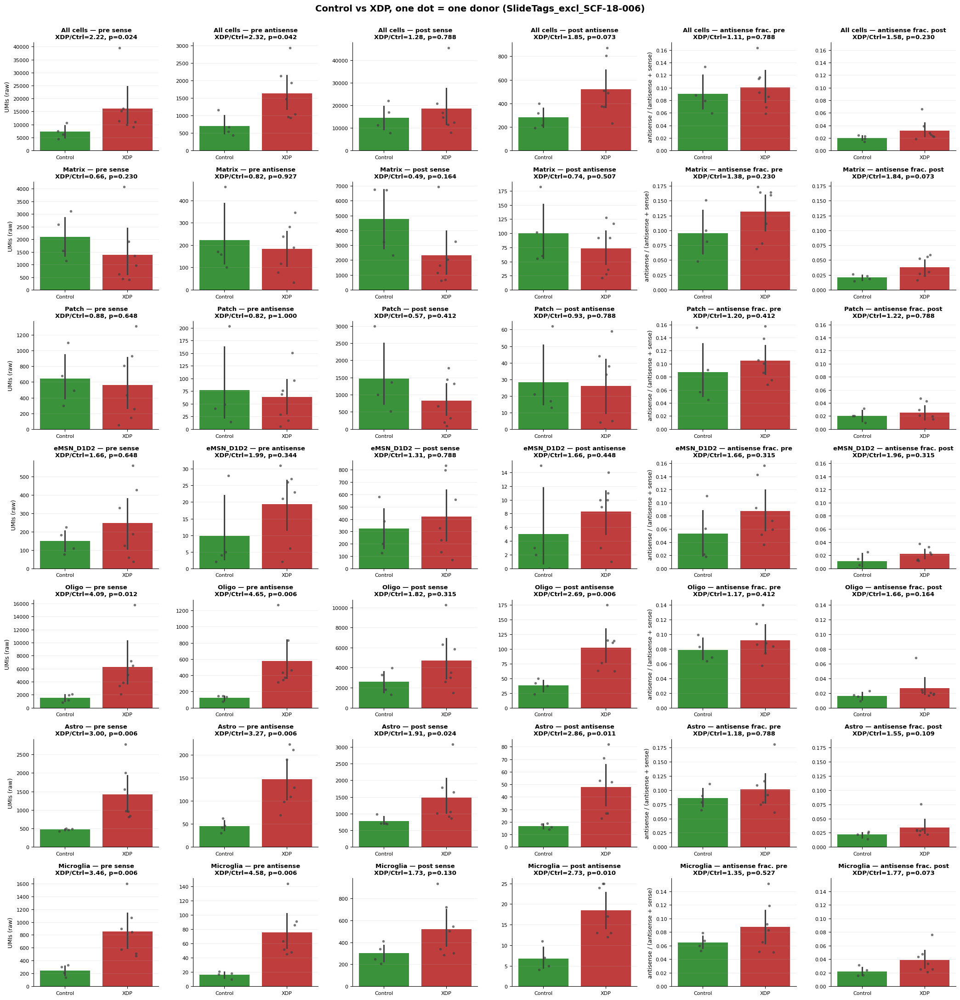

xdp_over_control                                 \
cells                            All cells Matrix  Patch eMSN_D1D2  Oligo   
value                                                                       
UMIs pre sense (raw)                 2.221  0.664  0.876     1.658  4.089   
UMIs pre antisense (raw)             2.324  0.825  0.825     1.993  4.653   
UMIs post sense (raw)                1.275  0.489  0.567     1.309  1.821   
UMIs post antisense (raw)            1.850  0.736  0.925     1.657  2.692   
antisense fraction pre               1.111  1.381  1.201     1.657  1.172   
antisense fraction post              1.580  1.843  1.216     1.959  1.665   

                                                   p                          \
cells                      Astro Microglia All cells Matrix  Patch eMSN_D1D2   
value                                                                          
UMIs pre sense (raw)       3.004     3.462     0.024  0.230  0.648     0.648   
UMIs pre antisense (raw)   3.267     4.580     0.042  0.927  1.000     0.344   
UMIs post sense (raw)      1.906     1.728     0.788  0.164  0.412     0.788   
UMIs post antisense (raw)  2.857     2.730     0.073  0.507  0.788     0.448   
antisense fraction pre     1.177     1.355     0.788  0.230  0.412     0.315   
antisense fraction post    1.553     1.775     0.230  0.073  0.788     0.315   

                                                   
cells                      Oligo  Astro Microglia  
value                                              
UMIs pre sense (raw)       0.012  0.006     0.006  
UMIs pre antisense (raw)   0.006  0.006     0.006  
UMIs post sense (raw)      0.315  0.024     0.130  
UMIs post antisense (raw)  0.006  0.011     0.010  
antisense fraction pre     0.412  0.788     0.527  
antisense fraction post    0.164  0.109     0.073

In [10]:
# Sense vs antisense in intron 32 (pre = before the SVA) and exon 33-38 (post)
# 2 versions: raw UMIs, and antisense fraction = antisense / (antisense + sense)
# (the fraction is independent of n cells / sequencing depth -> fair Control vs XDP comparison)
# levels: pooled by condition, per donor, per library, per cell type
from scipy.stats import mannwhitneyu

STRAND_COLORS = {"sense": "#2a78d6", "antisense": "#eb6834"}      # blue / orange
CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}       # green / red
WINDOW_COLORS = {"pre": "#7b3294", "post": "0.6"}
STRAND_COUNT_COLS = {
    "n_pre_sense_umis": ("pre", "sense"), "n_pre_antisense_umis": ("pre", "antisense"),
    "n_post_sense_umis": ("post", "sense"), "n_post_antisense_umis": ("post", "antisense"),
}
CT_SPLIT = ["Matrix", "Patch", "eMSN_D1D2", "Oligo", "Astro", "Microglia"]

# donors in EXCLUDE_DONORS (config cell) are removed here too
df_cells = obs_st_sub[~(obs_st_sub["donor_id"].isin(EXCLUDE_DONORS) | obs_st_sub["donor_number"].isin(EXCLUDE_DONORS))].copy()
df_cells["ct_for_deg"] = df_cells["ct_for_deg"].astype(str)
# short library label: donor + RNA index (RNA index alone is not unique across runs)
df_cells["library"] = df_cells["donor_number"].astype(str) + " " + df_cells["library_id"].str.split("_").str[-1]

donor_order = df_cells.sort_values(["condition", "donor_number"])["donor_number"].unique().tolist()
library_order = df_cells.sort_values(["condition", "donor_number", "library"])["library"].unique().tolist()


def strand_counts(df, group_cols):
    # summed UMIs per group, long: one row per group x window x strand
    out = df.groupby(group_cols, observed=True)[list(STRAND_COUNT_COLS)].sum().reset_index()
    out = out.melt(id_vars=group_cols, var_name="col", value_name="n_umis")
    out[["window", "strand"]] = out["col"].map(STRAND_COUNT_COLS).tolist()
    return out.drop(columns="col")


def antisense_fraction(df, group_cols):
    # antisense / (antisense + sense) on the summed UMIs, long: one row per group x window
    s = df.groupby(group_cols, observed=True)[list(STRAND_COUNT_COLS)].sum()
    return pd.concat([
        (s[f"n_{w}_antisense_umis"] / (s[f"n_{w}_antisense_umis"] + s[f"n_{w}_sense_umis"]))
        .rename("antisense_fraction").reset_index().assign(window=w)
        for w in ["pre", "post"]
    ], ignore_index=True)


def style(ax, title, ylabel="", rotate=False):
    ax.set_title(title, fontsize=9.5, fontweight="semibold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=9)
    ax.tick_params(axis="x", rotation=90 if rotate else 0, labelsize=8)
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)


# ---------------------------------------------------------------- 1. descriptive: pooled / per donor / per library
def plot_groups(df, group_cols, x, order, title, vertical=False):
    # raw UMIs (pre, post: sense vs antisense) + antisense fraction (pre vs post)
    counts, frac = strand_counts(df, group_cols), antisense_fraction(df, group_cols)
    nrows, ncols = (3, 1) if vertical else (1, 3)
    figsize = (18, 13) if vertical else (5 + 0.9 * len(order) * 1.5, 3.8)
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    rotate = len(order) > 4
    for ax, win in zip(axes[:2], ["pre", "post"]):
        sns.barplot(counts[counts["window"] == win], x=x, y="n_umis", hue="strand", order=order,
                    hue_order=["sense", "antisense"], palette=STRAND_COLORS, errorbar=None, ax=ax)
        ax.legend(title=None, frameon=False, fontsize=8)
        style(ax, f"{win} window, UMIs (raw)", "UMIs", rotate)
    sns.barplot(frac, x=x, y="antisense_fraction", hue="window", order=order,
                hue_order=["pre", "post"], palette=WINDOW_COLORS, errorbar=None, ax=axes[2])
    axes[2].legend(title=None, frameon=False, fontsize=8)
    style(axes[2], "antisense / (antisense + sense)", "antisense fraction", rotate)
    fig.suptitle(f"{title} ({ANALYSIS_NAME})", fontsize=13, fontweight="bold")
    fig.tight_layout()
    plt.show()


plot_groups(df_cells, ["condition"], "condition", ["Control", "XDP"], "Sense vs antisense, pooled by condition")
plot_groups(df_cells, ["donor_number", "condition"], "donor_number", donor_order, "Sense vs antisense, per donor")
plot_groups(df_cells, ["library", "donor_number", "condition"], "library", library_order,
            "Sense vs antisense, per library", vertical=True)


# ---------------------------------------------------------------- 2. Control vs XDP, one dot per donor: all cells + per cell type
def bar_dots_test(ax, d, y):
    # Control vs XDP bar + one dot per donor, returns fold change XDP / Control and Mann-Whitney p
    sns.barplot(d, x="condition", y=y, hue="condition", order=["Control", "XDP"],
                palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
    sns.stripplot(d, x="condition", y=y, order=["Control", "XDP"],
                  color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
    ctrl = d.loc[d["condition"] == "Control", y].dropna()
    xdp = d.loc[d["condition"] == "XDP", y].dropna()
    if len(ctrl) < 2 or len(xdp) < 2:
        return np.nan, np.nan
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    return xdp.mean() / ctrl.mean(), p


rows = [("All cells", df_cells)] + [(ct, df_cells[df_cells["ct_for_deg"] == ct]) for ct in CT_SPLIT]
test_results = []

fig, axes = plt.subplots(len(rows), 6, figsize=(21, 3.1 * len(rows)))
for r, (row_label, df_row) in enumerate(rows):
    counts = strand_counts(df_row, ["donor_number", "condition"])
    frac = antisense_fraction(df_row, ["donor_number", "condition"])

    # raw UMIs: 4 panels (window x strand); not normalized -> depends on n cells, descriptive only
    for c, (win, strand) in enumerate(STRAND_COUNT_COLS.values()):
        fc, p = bar_dots_test(axes[r, c], counts[(counts["window"] == win) & (counts["strand"] == strand)], "n_umis")
        test_results.append({"cells": row_label, "value": f"UMIs {win} {strand} (raw)", "xdp_over_control": fc, "p": p})
        style(axes[r, c], f"{row_label} — {win} {strand}\nXDP/Ctrl={fc:.2f}, p={p:.3f}", "UMIs (raw)" if c == 0 else "")

    # antisense fraction: 2 panels (pre, post), same y axis
    for c, win in enumerate(["pre", "post"], start=4):
        fc, p = bar_dots_test(axes[r, c], frac[frac["window"] == win], "antisense_fraction")
        test_results.append({"cells": row_label, "value": f"antisense fraction {win}", "xdp_over_control": fc, "p": p})
        style(axes[r, c], f"{row_label} — antisense frac. {win}\nXDP/Ctrl={fc:.2f}, p={p:.3f}",
              "antisense / (antisense + sense)" if c == 4 else "")
    axes[r, 5].sharey(axes[r, 4])

fig.suptitle(f"Control vs XDP, one dot = one donor ({ANALYSIS_NAME})", fontsize=14, fontweight="bold", y=1.0)
fig.tight_layout()
plt.show()

# summary: XDP / Control fold change and Mann-Whitney p (donors), all cells + per cell type
df_strand_tests = pd.DataFrame(test_results)
display(df_strand_tests.pivot_table(index="value", columns="cells", values=["xdp_over_control", "p"], sort=False)
        .round(3)[["xdp_over_control", "p"]])


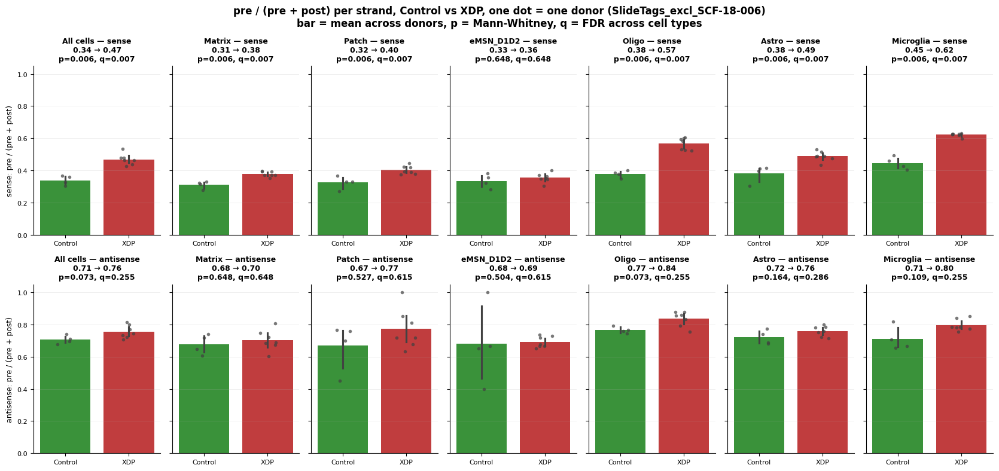

,strand,ct,n_control,n_xdp,mean_control,mean_xdp,diff_xdp_minus_control,p,q
0,sense,All cells,4,7,0.339,0.469,0.130,0.006,0.007
1,antisense,All cells,4,7,0.707,0.755,0.048,0.073,0.255
2,sense,Matrix,4,7,0.311,0.378,0.066,0.006,0.007
3,antisense,Matrix,4,7,0.678,0.704,0.026,0.648,0.648
4,sense,Patch,4,7,0.324,0.403,0.079,0.006,0.007
5,antisense,Patch,4,7,0.669,0.773,0.103,0.527,0.615
6,sense,eMSN_D1D2,4,7,0.334,0.355,0.021,0.648,0.648
7,antisense,eMSN_D1D2,4,7,0.679,0.692,0.013,0.504,0.615
8,sense,Oligo,4,7,0.378,0.566,0.188,0.006,0.007
9,antisense,Oligo,4,7,0.765,0.836,0.071,0.073,0.255


In [11]:
# Simple readout: per cell type and per strand, ratio = pre / (pre + post) per donor
# (pre = intron 32 before the SVA, post = exon 33-38); compare Control vs XDP
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}   # green / red
CT_SIMPLE = ["All cells", "Matrix", "Patch", "eMSN_D1D2", "Oligo", "Astro", "Microglia"]
STRANDS = ["sense", "antisense"]

# donors in EXCLUDE_DONORS (config cell) are removed here too
df_cells = obs_st_sub[~(obs_st_sub["donor_id"].isin(EXCLUDE_DONORS) | obs_st_sub["donor_number"].isin(EXCLUDE_DONORS))].copy()
df_cells["ct_for_deg"] = df_cells["ct_for_deg"].astype(str)

# one row per cell type x strand x donor
rows = []
for ct in CT_SIMPLE:
    d = df_cells if ct == "All cells" else df_cells[df_cells["ct_for_deg"] == ct]
    s = d.groupby(["donor_number", "condition"], observed=True)[
        ["n_pre_sense_umis", "n_post_sense_umis", "n_pre_antisense_umis", "n_post_antisense_umis"]].sum().reset_index()
    for strand in STRANDS:
        pre, post = s[f"n_pre_{strand}_umis"], s[f"n_post_{strand}_umis"]
        rows.append(pd.DataFrame({"ct": ct, "strand": strand, "donor_number": s["donor_number"],
                                  "condition": s["condition"], "pre": pre, "post": post,
                                  "pre_ratio": pre / (pre + post)}))
df_pre_ratio = pd.concat(rows, ignore_index=True).dropna(subset=["pre_ratio"])

# stats: mean across donors per group, Mann-Whitney Control vs XDP, FDR across cell types (per strand)
stats = []
for (strand, ct), d in df_pre_ratio.groupby(["strand", "ct"], sort=False):
    ctrl = d.loc[d["condition"] == "Control", "pre_ratio"]
    xdp = d.loc[d["condition"] == "XDP", "pre_ratio"]
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    stats.append({"strand": strand, "ct": ct, "n_control": len(ctrl), "n_xdp": len(xdp),
                  "mean_control": ctrl.mean(), "mean_xdp": xdp.mean(), "diff_xdp_minus_control": xdp.mean() - ctrl.mean(), "p": p})
df_pre_ratio_stats = pd.DataFrame(stats)
df_pre_ratio_stats["q"] = df_pre_ratio_stats.groupby("strand")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
st = df_pre_ratio_stats.set_index(["strand", "ct"])

# plot: one row per strand, one column per cell type, same y axis everywhere
fig, axes = plt.subplots(len(STRANDS), len(CT_SIMPLE), figsize=(2.4 * len(CT_SIMPLE), 4 * len(STRANDS)), sharey=True)
for r, strand in enumerate(STRANDS):
    for c, ct in enumerate(CT_SIMPLE):
        ax = axes[r, c]
        d = df_pre_ratio[(df_pre_ratio["strand"] == strand) & (df_pre_ratio["ct"] == ct)]
        sns.barplot(d, x="condition", y="pre_ratio", hue="condition", order=["Control", "XDP"],
                    palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
        sns.stripplot(d, x="condition", y="pre_ratio", order=["Control", "XDP"],
                      color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
        t = st.loc[(strand, ct)]
        ax.set_title(f"{ct} — {strand}\n{t['mean_control']:.2f} → {t['mean_xdp']:.2f}\np={t['p']:.3f}, q={t['q']:.3f}",
                     fontsize=9, fontweight="semibold")
        ax.set_xlabel("")
        ax.set_ylabel(f"{strand}: pre / (pre + post)" if c == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", linewidth=0.5, alpha=0.3)
        sns.despine(ax=ax)
fig.suptitle(f"pre / (pre + post) per strand, Control vs XDP, one dot = one donor ({ANALYSIS_NAME})\n"
             f"bar = mean across donors, p = Mann-Whitney, q = FDR across cell types", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

df_pre_ratio_stats.to_csv(OUT_DIR / f"32i_pre_ratio_per_strand_{ANALYSIS_NAME}.csv", index=False)
display(df_pre_ratio_stats.round(3))


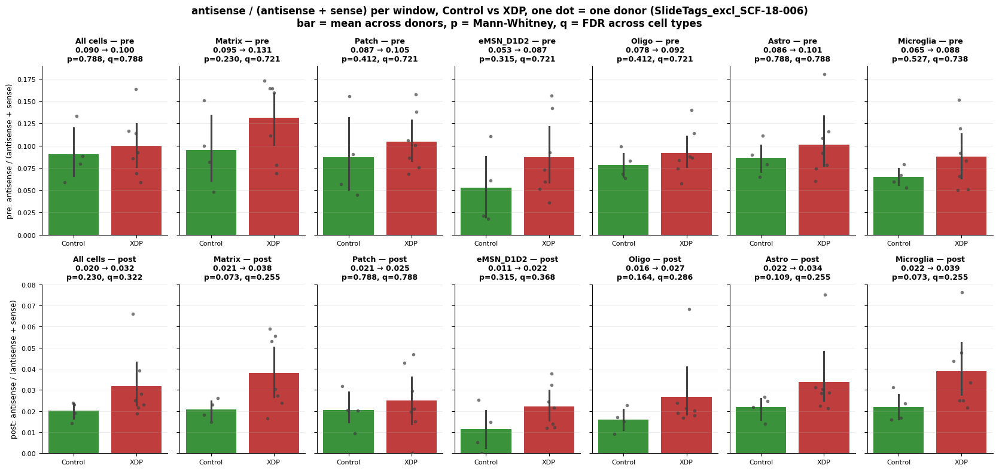

,window,ct,n_control,n_xdp,mean_control,mean_xdp,xdp_over_control,p,q
0,pre,All cells,4,7,0.090,0.100,1.111,0.788,0.788
1,post,All cells,4,7,0.020,0.032,1.580,0.230,0.322
2,pre,Matrix,4,7,0.095,0.131,1.381,0.230,0.721
3,post,Matrix,4,7,0.021,0.038,1.843,0.073,0.255
4,pre,Patch,4,7,0.087,0.105,1.201,0.412,0.721
5,post,Patch,4,7,0.021,0.025,1.216,0.788,0.788
6,pre,eMSN_D1D2,4,7,0.053,0.087,1.657,0.315,0.721
7,post,eMSN_D1D2,4,7,0.011,0.022,1.959,0.315,0.368
8,pre,Oligo,4,7,0.078,0.092,1.172,0.412,0.721
9,post,Oligo,4,7,0.016,0.027,1.665,0.164,0.286


In [12]:
# Simple readout: per cell type and per window, ratio = antisense / (antisense + sense) per donor
# (pre = intron 32 before the SVA, post = exon 33-38); compare Control vs XDP
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

CONDITION_COLORS = {"Control": "#2ca02c", "XDP": "#d62728"}   # green / red
CT_SIMPLE = ["All cells", "Matrix", "Patch", "eMSN_D1D2", "Oligo", "Astro", "Microglia"]
WINDOWS = ["pre", "post"]

# donors in EXCLUDE_DONORS (config cell) are removed here too
df_cells = obs_st_sub[~(obs_st_sub["donor_id"].isin(EXCLUDE_DONORS) | obs_st_sub["donor_number"].isin(EXCLUDE_DONORS))].copy()
df_cells["ct_for_deg"] = df_cells["ct_for_deg"].astype(str)

# one row per cell type x window x donor
rows = []
for ct in CT_SIMPLE:
    d = df_cells if ct == "All cells" else df_cells[df_cells["ct_for_deg"] == ct]
    s = d.groupby(["donor_number", "condition"], observed=True)[
        ["n_pre_sense_umis", "n_pre_antisense_umis", "n_post_sense_umis", "n_post_antisense_umis"]].sum().reset_index()
    for win in WINDOWS:
        sense, antisense = s[f"n_{win}_sense_umis"], s[f"n_{win}_antisense_umis"]
        rows.append(pd.DataFrame({"ct": ct, "window": win, "donor_number": s["donor_number"],
                                  "condition": s["condition"], "sense": sense, "antisense": antisense,
                                  "antisense_ratio": antisense / (antisense + sense)}))
df_as_ratio = pd.concat(rows, ignore_index=True).dropna(subset=["antisense_ratio"])

# stats: mean across donors per group, Mann-Whitney Control vs XDP, FDR across cell types (per window)
stats = []
for (win, ct), d in df_as_ratio.groupby(["window", "ct"], sort=False):
    ctrl = d.loc[d["condition"] == "Control", "antisense_ratio"]
    xdp = d.loc[d["condition"] == "XDP", "antisense_ratio"]
    _, p = mannwhitneyu(ctrl, xdp, alternative="two-sided")
    stats.append({"window": win, "ct": ct, "n_control": len(ctrl), "n_xdp": len(xdp),
                  "mean_control": ctrl.mean(), "mean_xdp": xdp.mean(), "xdp_over_control": xdp.mean() / ctrl.mean(), "p": p})
df_as_ratio_stats = pd.DataFrame(stats)
df_as_ratio_stats["q"] = df_as_ratio_stats.groupby("window")["p"].transform(lambda p: multipletests(p, method="fdr_bh")[1])
st = df_as_ratio_stats.set_index(["window", "ct"])

# plot: one row per window, one column per cell type, same y axis within a row
fig, axes = plt.subplots(len(WINDOWS), len(CT_SIMPLE), figsize=(2.4 * len(CT_SIMPLE), 4 * len(WINDOWS)), sharey="row")
for r, win in enumerate(WINDOWS):
    for c, ct in enumerate(CT_SIMPLE):
        ax = axes[r, c]
        d = df_as_ratio[(df_as_ratio["window"] == win) & (df_as_ratio["ct"] == ct)]
        sns.barplot(d, x="condition", y="antisense_ratio", hue="condition", order=["Control", "XDP"],
                    palette=CONDITION_COLORS, errorbar="ci", legend=False, ax=ax)
        sns.stripplot(d, x="condition", y="antisense_ratio", order=["Control", "XDP"],
                      color="0.25", size=4, jitter=0.15, alpha=0.7, ax=ax)
        t = st.loc[(win, ct)]
        ax.set_title(f"{ct} — {win}\n{t['mean_control']:.3f} → {t['mean_xdp']:.3f}\np={t['p']:.3f}, q={t['q']:.3f}",
                     fontsize=9, fontweight="semibold")
        ax.set_xlabel("")
        ax.set_ylabel(f"{win}: antisense / (antisense + sense)" if c == 0 else "", fontsize=9)
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", linewidth=0.5, alpha=0.3)
        sns.despine(ax=ax)
fig.suptitle(f"antisense / (antisense + sense) per window, Control vs XDP, one dot = one donor ({ANALYSIS_NAME})\n"
             f"bar = mean across donors, p = Mann-Whitney, q = FDR across cell types", fontsize=12, fontweight="bold")
fig.tight_layout()
plt.show()

df_as_ratio_stats.to_csv(OUT_DIR / f"32i_antisense_ratio_per_window_{ANALYSIS_NAME}.csv", index=False)
display(df_as_ratio_stats.round(3))


# Quanitty 32i

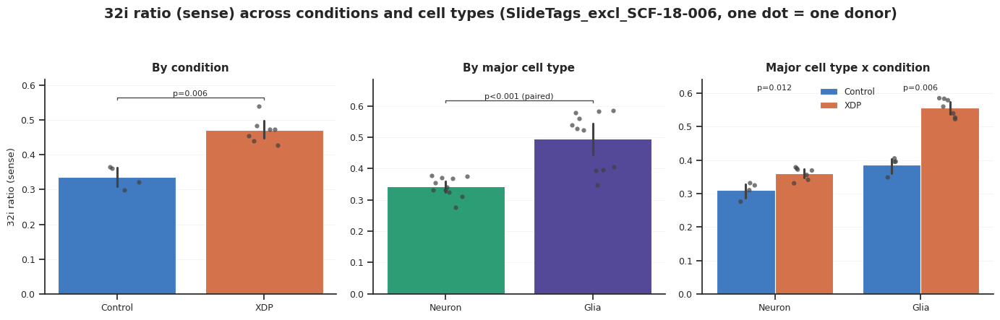

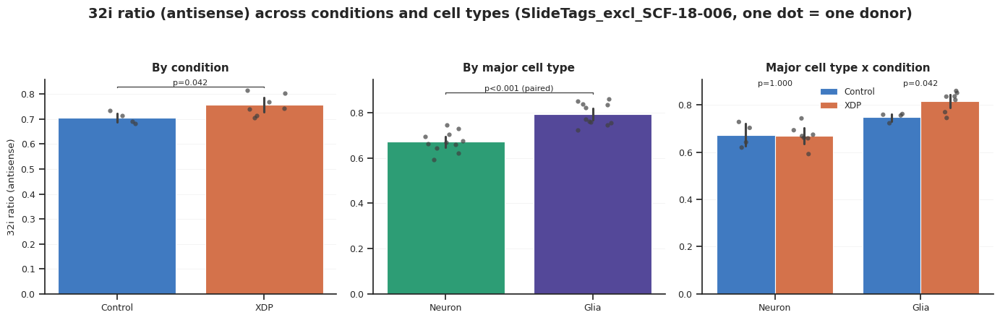

In [13]:
from scipy.stats import mannwhitneyu, wilcoxon

# fixed categorical color assignments — validated colorblind-safe pairs, never cycled
CONDITION_COLORS = {"Control": "#2a78d6", "XDP": "#eb6834"}   # blue / orange
CT_COLORS        = {"Neuron": "#1baf7a", "Glia": "#4a3aa7"}   # aqua / violet — distinct from condition slots

# the 2 versions of the 32i metric -- every analysis below is a function, called once per version
METRICS = {
    "pileup_metric_sense": "32i ratio (sense)",
    "pileup_metric_antisense": "32i ratio (antisense)",
}
# add "pileup_metric": "32i ratio (both strands)" or "pre_antisense_fraction": "antisense fraction (intron 32)" to run them too

sns.set_theme(style="ticks", context="notebook")


def style_ax(ax, title, ylabel=None):
    ax.set_title(title, fontsize=11, fontweight="semibold", pad=8)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel if ylabel else "", fontsize=9.5)
    ax.tick_params(labelsize=9)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)


def annotate_sig(ax, data, x, y, order, g1="Control", g2="XDP"):
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.06 if y_max != y_min else 0.02
    for i, cat in enumerate(order):
        a = data.loc[(data[x] == cat) & (data["condition"] == g1), y].dropna()
        b = data.loc[(data[x] == cat) & (data["condition"] == g2), y].dropna()
        if len(a) < 2 or len(b) < 2:
            continue
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        label = f"p={p:.3f}" if p >= 0.001 else "p<0.001"
        ax.text(i, y_max + offset, label, ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_max + offset * 3)


def annotate_sig_pair(ax, data, x, y, order, g1, g2, paired_on=None):
    """Direct two-group comparison (no sub-category split) — bracket + p-value.

    paired_on: column identifying the pairs (e.g. "donor_id" when the same donors
    are in both groups) -> Wilcoxon signed-rank instead of Mann-Whitney.
    """
    if paired_on:
        wide = data.pivot(index=paired_on, columns=x, values=y)[[g1, g2]].dropna()
        a, b = wide[g1], wide[g2]
    else:
        a = data.loc[data[x] == g1, y].dropna()
        b = data.loc[data[x] == g2, y].dropna()
    if len(a) < 2 or len(b) < 2:
        return
    if paired_on:
        _, p = wilcoxon(a, b)
    else:
        _, p = mannwhitneyu(a, b, alternative="two-sided")
    label = f"p={p:.3f}" if p >= 0.001 else "p<0.001"
    if paired_on:
        label += " (paired)"
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.08 if y_max != y_min else 0.02
    x1, x2, y_line = order.index(g1), order.index(g2), y_max + offset
    ax.plot([x1, x1, x2, x2], [y_line, y_line + offset * 0.3, y_line + offset * 0.3, y_line], lw=1, color="0.3")
    ax.text((x1 + x2) / 2, y_line + offset * 0.35, label, ha="center", va="bottom", fontsize=8)
    ax.set_ylim(top=y_line + offset * 3)


def plot_overview(df, metric, metric_label):
    # one dot = one donor: sum the UMIs of the donor's cell types, then recompute the metric
    # (summing UMIs = pseudobulk, so abundant cell types like Oligo weigh more)
    df_donor = add_32i_metrics(
        df.groupby(["donor_id", "condition"], observed=True)[COUNT_COLS].sum().reset_index()
    )
    df_donor_ct = add_32i_metrics(
        df.groupby(["donor_id", "condition", "ct"], observed=True)[COUNT_COLS].sum().reset_index()
    )

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.2))

    # A — by condition (one dot per donor)
    sns.barplot(df_donor, y=metric, x="condition", hue="condition",
                palette=CONDITION_COLORS, order=["Control", "XDP"], legend=False,
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax1)
    sns.stripplot(df_donor, y=metric, x="condition", order=["Control", "XDP"],
                  color="0.25", size=4.5, jitter=0.15, alpha=0.7, ax=ax1)
    annotate_sig_pair(ax1, df_donor, "condition", metric, ["Control", "XDP"], "Control", "XDP")
    style_ax(ax1, "By condition", ylabel=metric_label)

    # B — by major cell type (one dot per donor; same donors in both -> paired test)
    sns.barplot(df_donor_ct, y=metric, x="ct", hue="ct",
                palette=CT_COLORS, order=["Neuron", "Glia"], legend=False,
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax2)
    sns.stripplot(df_donor_ct, y=metric, x="ct", order=["Neuron", "Glia"],
                  color="0.25", size=4.5, jitter=0.15, alpha=0.7, ax=ax2)
    annotate_sig_pair(ax2, df_donor_ct, "ct", metric, ["Neuron", "Glia"], "Neuron", "Glia", paired_on="donor_id")
    style_ax(ax2, "By major cell type")

    # C — major cell type x condition (one dot per donor)
    sns.barplot(df_donor_ct, y=metric, x="ct", hue="condition",
                palette=CONDITION_COLORS, hue_order=["Control", "XDP"], order=["Neuron", "Glia"],
                errorbar="ci", edgecolor="white", linewidth=0.8, ax=ax3)
    sns.stripplot(df_donor_ct, y=metric, x="ct", hue="condition",
                  hue_order=["Control", "XDP"], order=["Neuron", "Glia"], dodge=True,
                  palette={"Control": "0.25", "XDP": "0.25"}, size=4.5, jitter=0.15, alpha=0.7,
                  legend=False, ax=ax3)
    annotate_sig(ax3, df_donor_ct, "ct", metric, ["Neuron", "Glia"])
    ax3.legend(title=None, fontsize=8.5, frameon=False, loc="best")
    style_ax(ax3, "Major cell type x condition")

    fig.suptitle(f"{metric_label} across conditions and cell types ({ANALYSIS_NAME}, one dot = one donor)",
                 fontsize=14, fontweight="bold", y=1.05)
    fig.tight_layout()
    plt.show()


for metric, metric_label in METRICS.items():
    plot_overview(df_pseudobulk_all, metric, metric_label)


# Test change in ratio

In [14]:
cell_types = ["Matrix", "Patch", "eMSN_D1D2", "non-MSN", "Oligo", "Astro", "Microglia"]  # swap for whatever cell type you want to analyze

In [15]:
# run manhwitney test on eahc cell type
def test_condition(df, metric, cell_types):
    for ct in cell_types:

        tmp = df[df["ct_for_deg"] == ct]

        control = tmp[tmp["condition"] == "Control"][metric].dropna()
        xdp = tmp[tmp["condition"] == "XDP"][metric].dropna()

        stat, pval = mannwhitneyu(control, xdp, alternative="two-sided")

        print(f"{ct}: n_control={len(control)}, n_xdp={len(xdp)}, Mann-Whitney U test p-value = {pval:.4e}")


for metric, metric_label in METRICS.items():
    print(f"\n{metric_label}\n{'=' * 60}")
    test_condition(df_pseudobulk_all, metric, cell_types)


32i ratio (sense)
Matrix: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03
Patch: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03
eMSN_D1D2: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.4848e-01
non-MSN: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03
Oligo: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03
Astro: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03
Microglia: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.0606e-03

32i ratio (antisense)
Matrix: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 6.4848e-01
Patch: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 5.2727e-01
eMSN_D1D2: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 5.0443e-01
non-MSN: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 1.0000e+00
Oligo: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 7.2727e-02
Astro: n_control=4, n_xdp=7, Mann-Whitney U test p-value = 1.6364e-01
Microglia: n_control=4, n_xdp=

/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


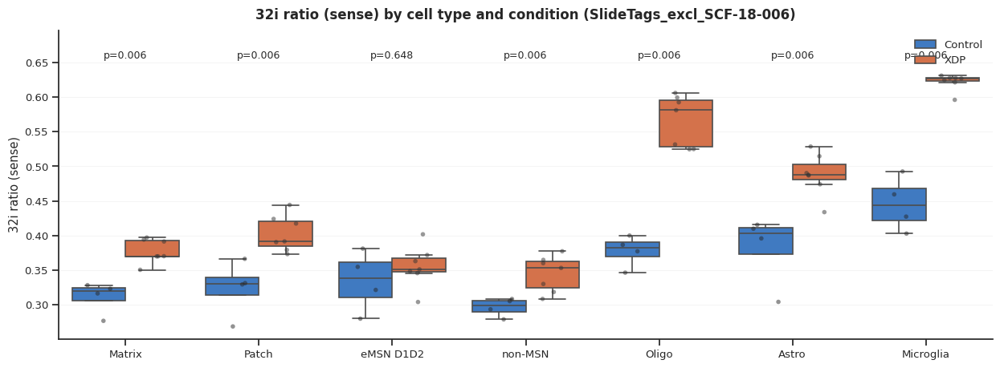

/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


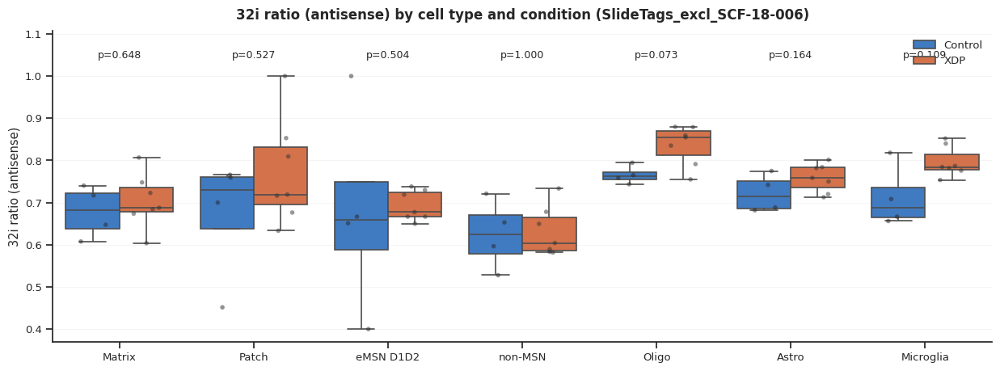

In [16]:
def annotate_pvals(ax, data, x, y, hue, order, g1="Control", g2="XDP"):
    y_max, y_min = data[y].max(), data[y].min()
    offset = (y_max - y_min) * 0.06 if y_max != y_min else 0.05
    for i, cat in enumerate(order):
        a = data.loc[(data[x] == cat) & (data[hue] == g1), y].dropna()
        b = data.loc[(data[x] == cat) & (data[hue] == g2), y].dropna()
        if len(a) < 2 or len(b) < 2:
            continue
        _, pval = mannwhitneyu(a, b, alternative="two-sided")
        label = f"p={pval:.3f}" if pval >= 0.001 else "p<0.001"
        ax.text(i, y_max + offset, label, ha="center", va="bottom", fontsize=9)
    ax.set_ylim(top=y_max + offset * 3)


def plot_pileup(data, y, order, ylabel="32i Ratio", hue="condition", hue_order=("Control", "XDP"), palette=CONDITION_COLORS):
    sns.set_theme(style="ticks", context="notebook")
    fig, ax = plt.subplots(figsize=(15, 5))

    sns.boxplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
                palette=palette, hue_order=list(hue_order),
                showfliers=False, linewidth=1.2, ax=ax)
    sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
                  hue_order=list(hue_order), dodge=True, color="0.2",
                  size=4, alpha=0.5, jitter=0.2, legend=False, ax=ax)

    annotate_pvals(ax, data, "ct_for_deg", y, hue, order, *hue_order)

    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=10.5)
    ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])
    ax.tick_params(labelsize=9.5)
    ax.grid(axis="y", linewidth=0.5, alpha=0.3)
    sns.despine(ax=ax)
    ax.legend(title=None, fontsize=9.5, frameon=False, loc="upper right")

    ax.set_title(f"{ylabel} by cell type and {hue} ({ANALYSIS_NAME})", fontsize=12, fontweight="semibold", pad=10)
    plt.show()


for metric, metric_label in METRICS.items():
    plot_pileup(df_pseudobulk_all, metric, cell_types, ylabel=metric_label)

# Corr ratio
Covariates are taken from `obs` (one value per donor)

In [17]:
covariate_per_cell_type = ["Age_of_Death", "Age_of_Onset", "repeat_length", "Disease_duration"]
XDP_ONLY_COVARIATES = {"repeat_length", "Disease_duration", "Age_of_Onset"}

# donor metadata from obs ("not_applicable" for controls -> NaN)
df_donor_meta = (
    obs_st[["donor_id", "age_at_death", "age_at_onset", "repeat_length"]]
    .drop_duplicates("donor_id")
    .rename(columns={"age_at_death": "Age_of_Death", "age_at_onset": "Age_of_Onset"})
)
for col in ["Age_of_Death", "Age_of_Onset", "repeat_length"]:
    df_donor_meta[col] = pd.to_numeric(df_donor_meta[col].astype(str), errors="coerce")
df_donor_meta["Disease_duration"] = df_donor_meta["Age_of_Death"] - df_donor_meta["Age_of_Onset"]
display(df_donor_meta)

df_cov = df_pseudobulk_all.merge(df_donor_meta, on="donor_id", how="left")

df_cov

,donor_id,Age_of_Death,Age_of_Onset,repeat_length,Disease_duration
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1,SCF-18-003,41,32.0,42.0,9.0
260313_SL-EXA_0758_B23GHNHLT4---SI-TT-B10---AAACCAAAGGGGGCAT-1,SCF-20-025,58,51.0,38.0,7.0
260313_SL-EXA_0758_B23GHNHLT4---SI-TT-C2---AAACCAAAGAAAGCTA-1,SCF-19-014,32,30.0,50.0,2.0
260313_SL-EXA_0758_B23GHNHLT4---SI-TT-C6---AAACCAAAGACCCACG-1,SCF-20-024,46,39.0,46.0,7.0
260415_SL-EXF_0678_B23K5JWLT4---SI-TT-D7---AAACCAAAGAAGGCTG-1,SCF-23-068,43,NaN,NaN,NaN
260415_SL-EXF_0678_B23K5JWLT4---SI-TT-E7---AAACCAAAGAGAGAGA-1,SCF-20-026,61,39.0,39.0,22.0
260415_SL-EXF_0678_B23K5JWLT4---SI-TT-E10---AAACCAGCAAAACCGA-1,SCF-22-057,66,NaN,NaN,NaN
260415_SL-EXF_0678_B23K5JWLT4---SI-TT-F10---AAACCAAAGCAGCCCA-1,SCF-22-043,52,46.0,40.0,6.0
240911_SL-EXD_0362_A22FLV2LT4---SI-TT-E1---AAACCAAAGAAGGTTA-1,SCF-18-006,51,46.0,35.0,5.0
260721_SL-EXB_0892_B23Y3GKLT4---SI-TT-H5---AAACCAAAGCTCTCAT-1,SCF-21-032,66,57.0,34.0,9.0


,donor_id,condition,ct_for_deg,n_pre_umis,n_post_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,n_cells,...,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction,ct,Age_of_Death,Age_of_Onset,repeat_length,Disease_duration
0,SCF-18-003,XDP,Astro,1750.0,1694.0,1563.0,190.0,1642.0,53.0,8573,...,0.429002,0.487676,0.781893,0.108386,0.031268,Glia,41,32.0,42.0,9.0
1,SCF-18-003,XDP,Matrix,732.0,1167.0,616.0,117.0,1141.0,28.0,3431,...,0.313274,0.350598,0.806897,0.159618,0.023952,Neuron,41,32.0,42.0,9.0
2,SCF-18-003,XDP,Microglia,1206.0,747.0,1065.0,144.0,722.0,25.0,6712,...,0.540052,0.595971,0.852071,0.119107,0.033467,Glia,41,32.0,42.0,9.0
3,SCF-18-003,XDP,OPC,393.0,243.0,344.0,49.0,237.0,6.0,2245,...,0.540487,0.592083,0.890909,0.124682,0.024691,Glia,41,32.0,42.0,9.0
4,SCF-18-003,XDP,Oligo,7284.0,5967.0,6469.0,834.0,5855.0,114.0,47008,...,0.470283,0.524911,0.879747,0.114200,0.019099,Glia,41,32.0,42.0,9.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,SCF-23-075,Control,Oligo,904.0,1338.0,829.0,75.0,1315.0,23.0,11393,...,0.329478,0.386660,0.765306,0.082965,0.017190,Glia,60,NaN,NaN,NaN
95,SCF-23-075,Control,Patch,1301.0,3053.0,1100.0,203.0,2992.0,62.0,6127,...,0.236595,0.268817,0.766038,0.155794,0.020301,Neuron,60,NaN,NaN,NaN
96,SCF-23-075,Control,eMSN_D1D2,254.0,596.0,226.0,28.0,581.0,15.0,1668,...,0.236611,0.280050,0.651163,0.110236,0.025168,Neuron,60,NaN,NaN,NaN
97,SCF-23-075,Control,eMSN_NUDAP,112.0,230.0,95.0,17.0,226.0,4.0,693,...,0.261531,0.295950,0.809524,0.151786,0.017391,Neuron,60,NaN,NaN,NaN



Analyzing covariate: Age_of_Death


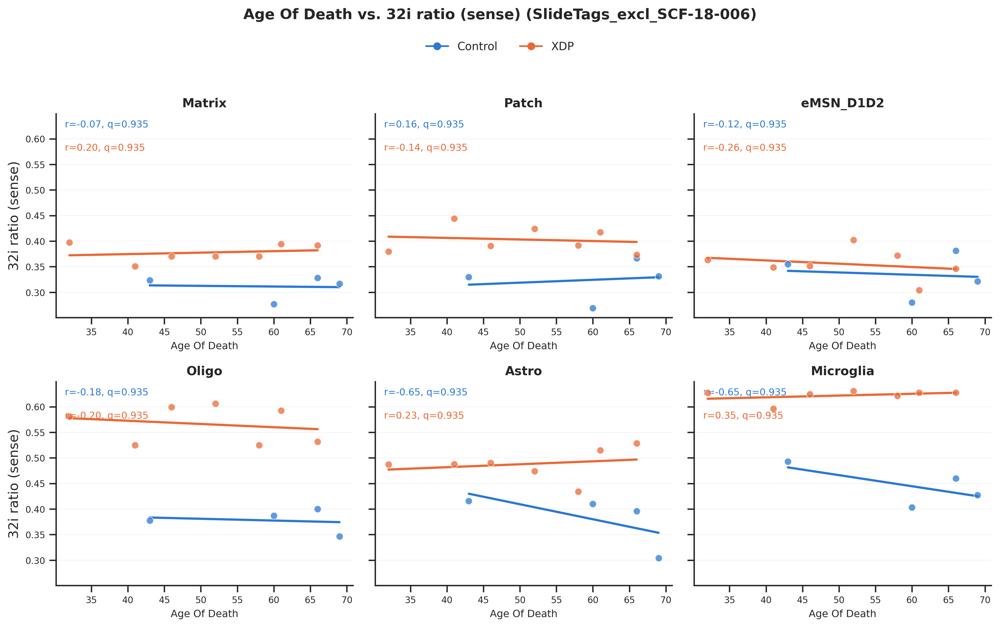

Pearson Correlation: Age_of_Death vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | Control    | Slope = -0.000 | r = -0.065 | p = 9.350e-01 | q(FDR) = 9.350e-01
Matrix               | XDP        | Slope =  0.000 | r =  0.202 | p = 6.640e-01 | q(FDR) = 9.350e-01
Patch                | Control    | Slope =  0.001 | r =  0.161 | p = 8.394e-01 | q(FDR) = 9.350e-01
Patch                | XDP        | Slope = -0.000 | r = -0.140 | p = 7.649e-01 | q(FDR) = 9.350e-01
eMSN_D1D2            | Control    | Slope = -0.000 | r = -0.120 | p = 8.803e-01 | q(FDR) = 9.350e-01
eMSN_D1D2            | XDP        | Slope = -0.001 | r = -0.259 | p = 5.745e-01 | q(FDR) = 9.350e-01
Oligo                | Control    | Slope = -0.000 | r = -0.177 | p = 8.227e-01 | q(FDR) = 9.350e-01
Oligo                | XDP        | Slope = -0.001 | r = -0.204 | p = 6.606e-01 | q(FDR) = 9.350e-01
Astro                | Control    | Slope = -0.003 | r = -0.

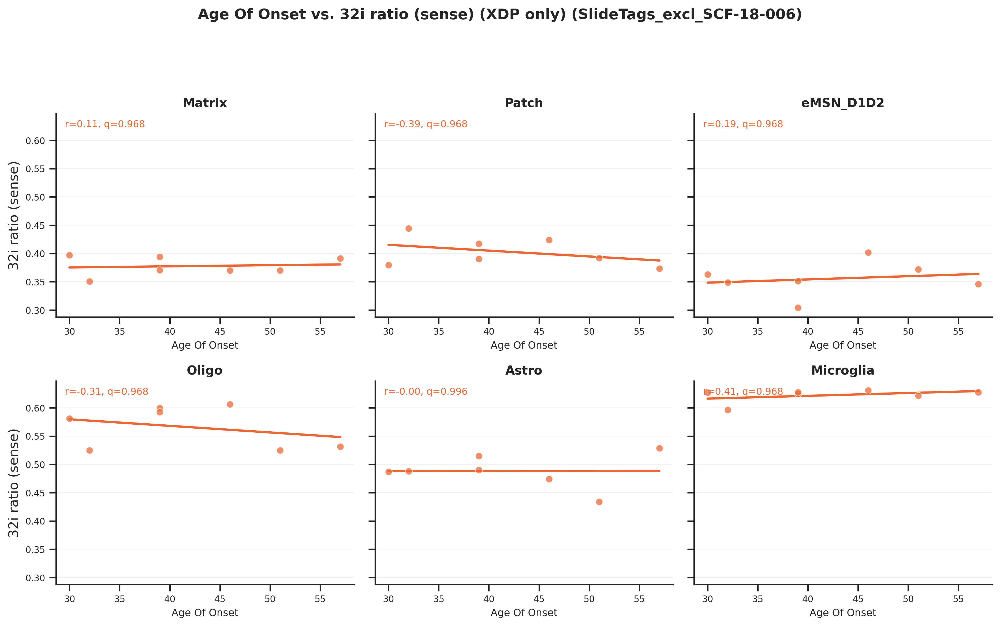

Pearson Correlation: Age_of_Onset vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.000 | r =  0.115 | p = 8.068e-01 | q(FDR) = 9.681e-01
Patch                | XDP        | Slope = -0.001 | r = -0.388 | p = 3.895e-01 | q(FDR) = 9.681e-01
eMSN_D1D2            | XDP        | Slope =  0.001 | r =  0.189 | p = 6.843e-01 | q(FDR) = 9.681e-01
Oligo                | XDP        | Slope = -0.001 | r = -0.310 | p = 4.993e-01 | q(FDR) = 9.681e-01
Astro                | XDP        | Slope = -0.000 | r = -0.002 | p = 9.961e-01 | q(FDR) = 9.961e-01
Microglia            | XDP        | Slope =  0.000 | r =  0.410 | p = 3.611e-01 | q(FDR) = 9.681e-01

Analyzing covariate: repeat_length


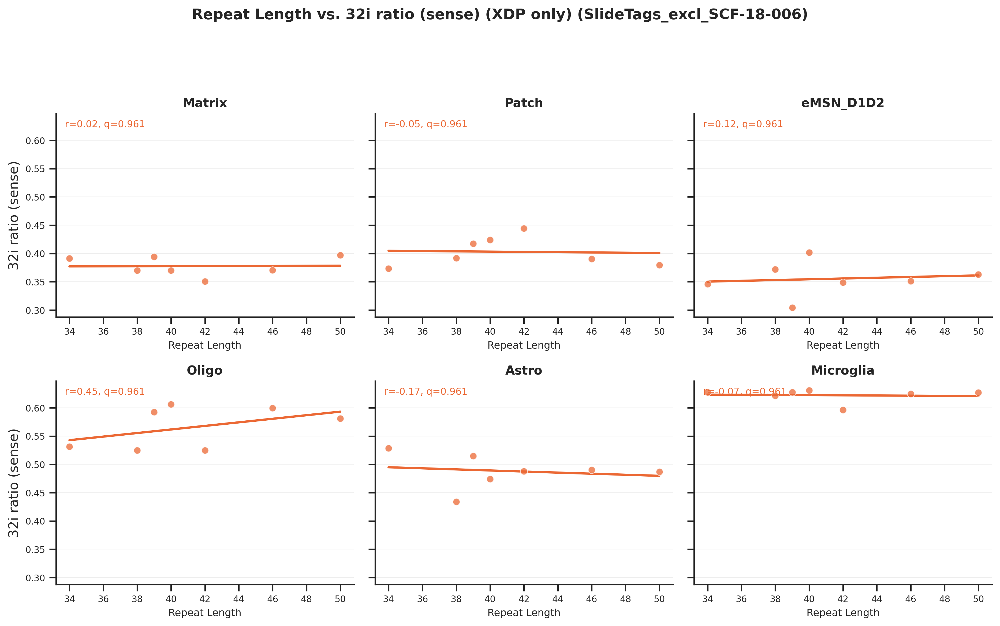

Pearson Correlation: repeat_length vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.000 | r =  0.023 | p = 9.609e-01 | q(FDR) = 9.609e-01
Patch                | XDP        | Slope = -0.000 | r = -0.049 | p = 9.164e-01 | q(FDR) = 9.609e-01
eMSN_D1D2            | XDP        | Slope =  0.001 | r =  0.123 | p = 7.932e-01 | q(FDR) = 9.609e-01
Oligo                | XDP        | Slope =  0.003 | r =  0.452 | p = 3.084e-01 | q(FDR) = 9.609e-01
Astro                | XDP        | Slope = -0.001 | r = -0.166 | p = 7.216e-01 | q(FDR) = 9.609e-01
Microglia            | XDP        | Slope = -0.000 | r = -0.069 | p = 8.831e-01 | q(FDR) = 9.609e-01

Analyzing covariate: Disease_duration


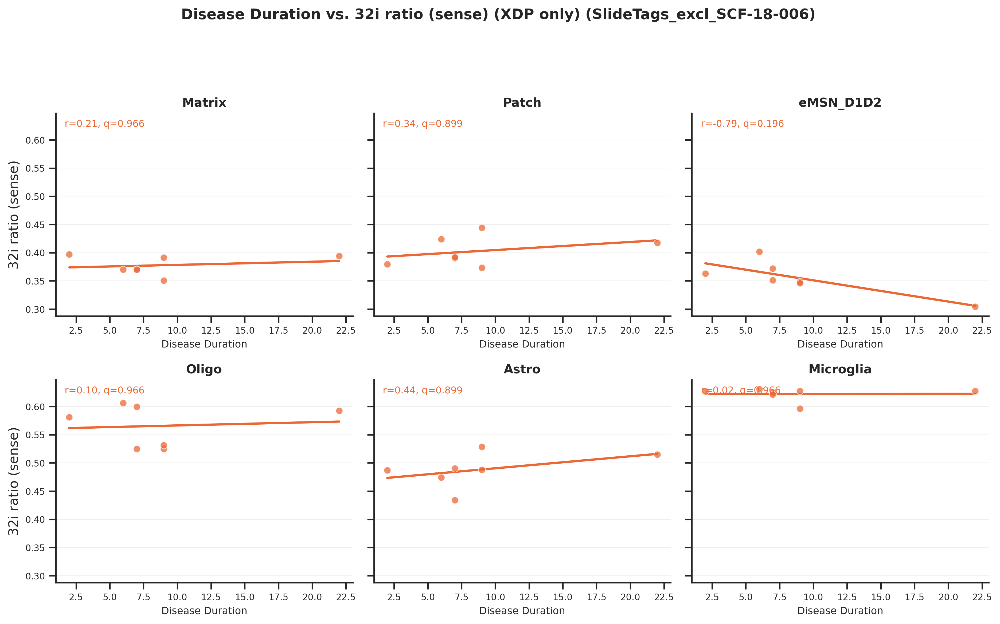

Pearson Correlation: Disease_duration vs. 32i ratio (sense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.001 | r =  0.206 | p = 6.576e-01 | q(FDR) = 9.665e-01
Patch                | XDP        | Slope =  0.001 | r =  0.344 | p = 4.494e-01 | q(FDR) = 8.988e-01
eMSN_D1D2            | XDP        | Slope = -0.004 | r = -0.795 | p = 3.264e-02 | q(FDR) = 1.958e-01
Oligo                | XDP        | Slope =  0.001 | r =  0.097 | p = 8.356e-01 | q(FDR) = 9.665e-01
Astro                | XDP        | Slope =  0.002 | r =  0.440 | p = 3.227e-01 | q(FDR) = 8.988e-01
Microglia            | XDP        | Slope =  0.000 | r =  0.020 | p = 9.665e-01 | q(FDR) = 9.665e-01

Analyzing covariate: Age_of_Death


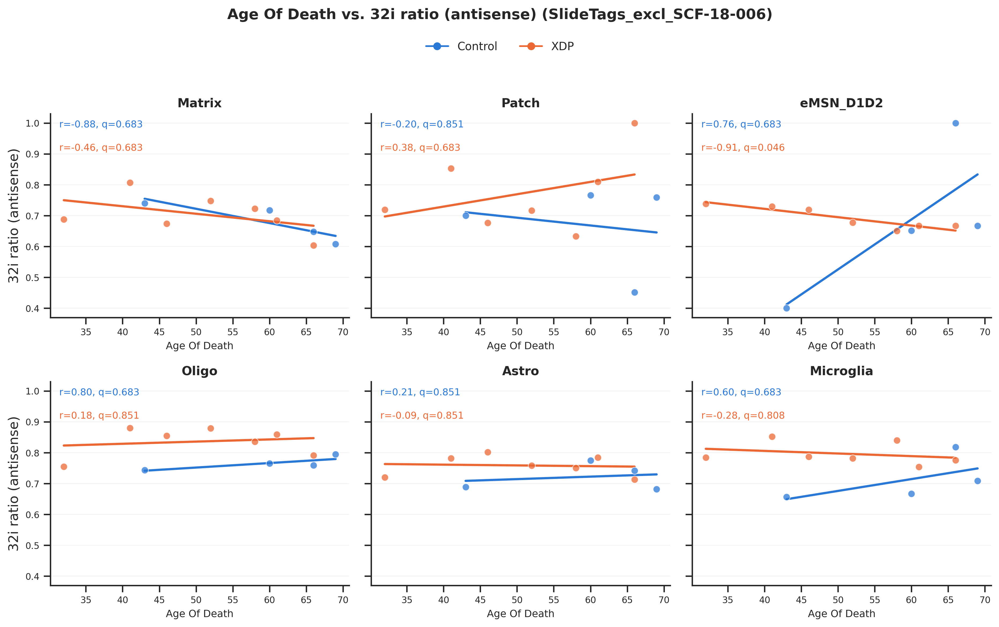

Pearson Correlation: Age_of_Death vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | Control    | Slope = -0.005 | r = -0.877 | p = 1.227e-01 | q(FDR) = 6.832e-01
Matrix               | XDP        | Slope = -0.002 | r = -0.456 | p = 3.033e-01 | q(FDR) = 6.832e-01
Patch                | Control    | Slope = -0.003 | r = -0.197 | p = 8.027e-01 | q(FDR) = 8.510e-01
Patch                | XDP        | Slope =  0.004 | r =  0.382 | p = 3.972e-01 | q(FDR) = 6.832e-01
eMSN_D1D2            | Control    | Slope =  0.016 | r =  0.764 | p = 2.356e-01 | q(FDR) = 6.832e-01
eMSN_D1D2            | XDP        | Slope = -0.003 | r = -0.915 | p = 3.870e-03 | q(FDR) = 4.644e-02
Oligo                | Control    | Slope =  0.001 | r =  0.796 | p = 2.043e-01 | q(FDR) = 6.832e-01
Oligo                | XDP        | Slope =  0.001 | r =  0.180 | p = 6.995e-01 | q(FDR) = 8.510e-01
Astro                | Control    | Slope =  0.001 | r =

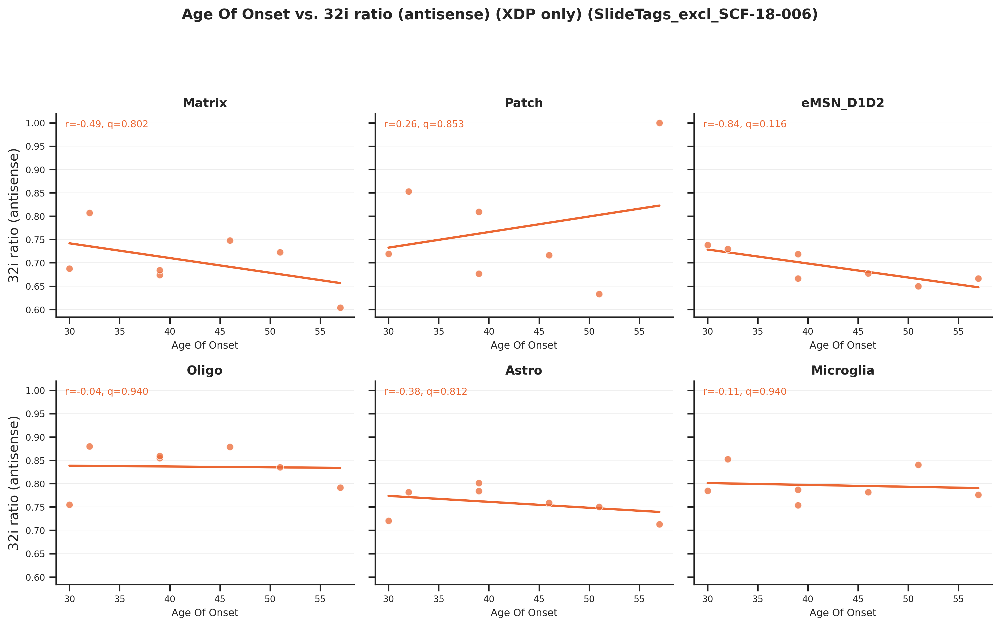

Pearson Correlation: Age_of_Onset vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope = -0.003 | r = -0.487 | p = 2.674e-01 | q(FDR) = 8.021e-01
Patch                | XDP        | Slope =  0.003 | r =  0.263 | p = 5.690e-01 | q(FDR) = 8.535e-01
eMSN_D1D2            | XDP        | Slope = -0.003 | r = -0.835 | p = 1.928e-02 | q(FDR) = 1.157e-01
Oligo                | XDP        | Slope = -0.000 | r = -0.035 | p = 9.398e-01 | q(FDR) = 9.398e-01
Astro                | XDP        | Slope = -0.001 | r = -0.376 | p = 4.062e-01 | q(FDR) = 8.124e-01
Microglia            | XDP        | Slope = -0.000 | r = -0.109 | p = 8.163e-01 | q(FDR) = 9.398e-01

Analyzing covariate: repeat_length


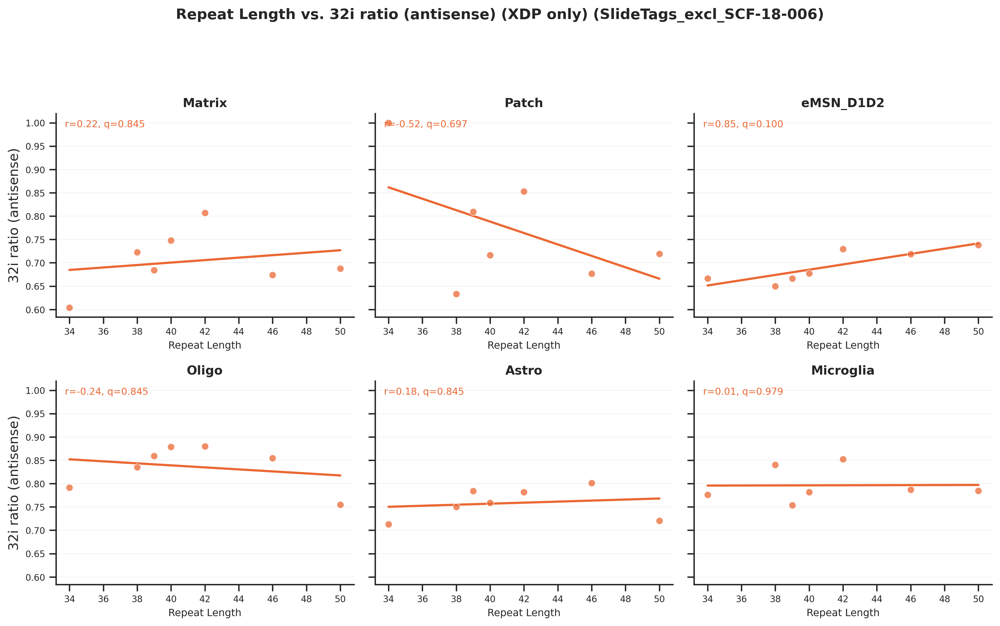

Pearson Correlation: repeat_length vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope =  0.003 | r =  0.219 | p = 6.364e-01 | q(FDR) = 8.453e-01
Patch                | XDP        | Slope = -0.012 | r = -0.519 | p = 2.325e-01 | q(FDR) = 6.975e-01
eMSN_D1D2            | XDP        | Slope =  0.006 | r =  0.845 | p = 1.668e-02 | q(FDR) = 1.001e-01
Oligo                | XDP        | Slope = -0.002 | r = -0.244 | p = 5.974e-01 | q(FDR) = 8.453e-01
Astro                | XDP        | Slope =  0.001 | r =  0.177 | p = 7.044e-01 | q(FDR) = 8.453e-01
Microglia            | XDP        | Slope =  0.000 | r =  0.012 | p = 9.792e-01 | q(FDR) = 9.792e-01

Analyzing covariate: Disease_duration


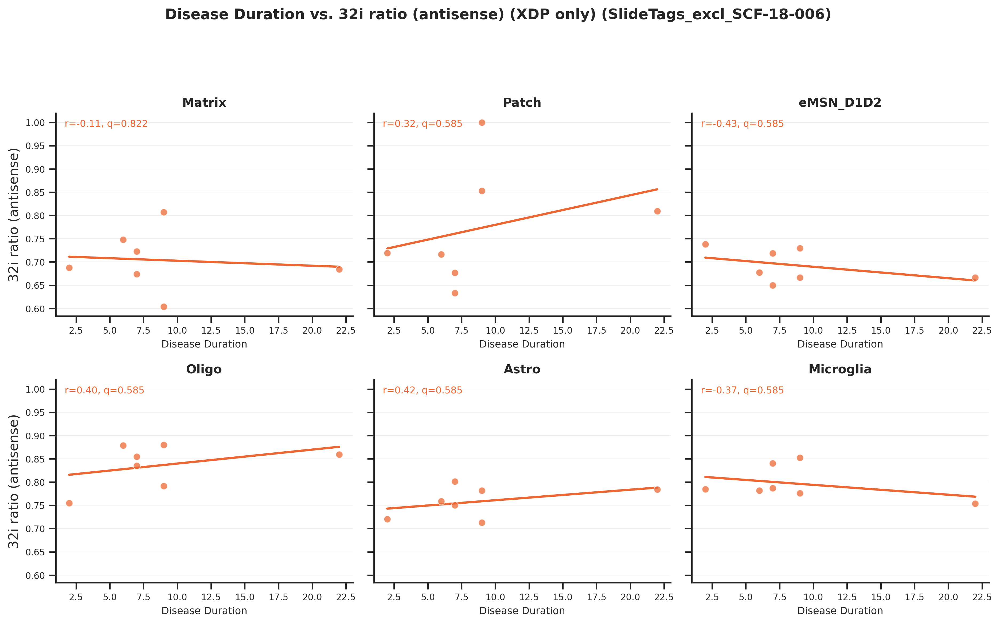

Pearson Correlation: Disease_duration vs. 32i ratio (antisense)
---------------------------------------------------------------------------
Matrix               | XDP        | Slope = -0.001 | r = -0.105 | p = 8.220e-01 | q(FDR) = 8.220e-01
Patch                | XDP        | Slope =  0.006 | r =  0.318 | p = 4.875e-01 | q(FDR) = 5.850e-01
eMSN_D1D2            | XDP        | Slope = -0.002 | r = -0.434 | p = 3.302e-01 | q(FDR) = 5.850e-01
Oligo                | XDP        | Slope =  0.003 | r =  0.400 | p = 3.735e-01 | q(FDR) = 5.850e-01
Astro                | XDP        | Slope =  0.002 | r =  0.424 | p = 3.434e-01 | q(FDR) = 5.850e-01
Microglia            | XDP        | Slope = -0.002 | r = -0.370 | p = 4.143e-01 | q(FDR) = 5.850e-01


,metric,covariate,ct_for_deg,condition,n_donors,slope,pearson_r,p,q_fdr,spearman_rho,p_spearman
35,pileup_metric_antisense,Age_of_Death,eMSN_D1D2,XDP,7,-0.002705,-0.914941,0.003870,0.046435,-0.882919,0.008450
50,pileup_metric_antisense,repeat_length,eMSN_D1D2,XDP,7,0.005630,0.845008,0.016679,0.100077,0.900937,0.005621
44,pileup_metric_antisense,Age_of_Onset,eMSN_D1D2,XDP,7,-0.002998,-0.835418,0.019275,0.115653,-0.845455,0.016564
26,pileup_metric_sense,Disease_duration,eMSN_D1D2,XDP,7,-0.003768,-0.794937,0.032637,0.195825,-0.854687,0.014274
30,pileup_metric_antisense,Age_of_Death,Matrix,Control,4,-0.004628,-0.877318,0.122682,0.683161,-1.000000,0.000000
36,pileup_metric_antisense,Age_of_Death,Oligo,Control,4,0.001461,0.795720,0.204280,0.683161,0.800000,0.200000
49,pileup_metric_antisense,repeat_length,Patch,XDP,7,-0.012240,-0.519129,0.232484,0.697453,-0.214286,0.644512
34,pileup_metric_antisense,Age_of_Death,eMSN_D1D2,Control,4,0.016195,0.764360,0.235640,0.683161,0.800000,0.200000
42,pileup_metric_antisense,Age_of_Onset,Matrix,XDP,7,-0.003155,-0.487299,0.267352,0.802055,-0.342356,0.452251
31,pileup_metric_antisense,Age_of_Death,Matrix,XDP,7,-0.002434,-0.456441,0.303251,0.683161,-0.500000,0.253170


In [18]:
from scipy.stats import linregress, spearmanr
from statsmodels.stats.multitest import multipletests

cell_types = ["Matrix", "Patch", "eMSN_D1D2", "Oligo", "Astro", "Microglia"]  # swap for whatever cell type you want to analyze

sns.set_theme(style="ticks", context="notebook")


def fit_and_annotate(ax, x, y, color, label_y, res, qvalue):
    """Scatter + regression line + r/q annotation for one condition on ax.

    res/qvalue are precomputed upstream so the FDR correction can see every
    p-value for this covariate before any of them get plotted.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    mask = ~np.isnan(x) & ~np.isnan(y)
    x, y = x[mask], y[mask]

    ax.scatter(x, y, s=40, color=color, alpha=0.75, edgecolor="white", linewidth=0.6, zorder=3)

    if res is None:
        ax.text(0.03, label_y, "insufficient data", transform=ax.transAxes,
                 fontsize=8.5, color=color, va="top", style="italic")
        return

    xs = np.linspace(x.min(), x.max(), 100)
    ax.plot(xs, res.intercept + res.slope * xs, color=color, linewidth=2, zorder=2)

    q_label = "q<0.001" if qvalue < 0.001 else f"q={qvalue:.3f}"
    ax.text(0.03, label_y, f"r={res.rvalue:.2f}, {q_label}", transform=ax.transAxes,
             fontsize=8.5, color=color, va="top", fontweight="medium")


def plot_covariate_correlations(df_cov, metric, metric_label, covariates, cell_types, n_cols=3):
    """One figure per covariate (one panel per cell type), returns the stats as a df."""

    plot_cell_types = [ct for ct in cell_types if ct != "non-MSN"]  # drop non-MSN so grid is a clean 3x2
    n_rows = -(-len(plot_cell_types) // n_cols)  # ceil division
    results = []

    for COV in covariates:

        print(f"\nAnalyzing covariate: {COV}\n{'=' * 60}")

        conditions = ["XDP"] if COV in XDP_ONLY_COVARIATES else ["Control", "XDP"]
        tmp_df = df_cov[df_cov["ct_for_deg"].isin(plot_cell_types)].copy()
        if COV in XDP_ONLY_COVARIATES:
            tmp_df = tmp_df[tmp_df["condition"] == "XDP"]

        # single pass: fit every (cell type, condition) combo once, so the FDR
        # correction below sees the full family of p-values for this covariate
        records = {}
        for ct in plot_cell_types:
            for cond in conditions:
                s = tmp_df[(tmp_df["ct_for_deg"] == ct) & (tmp_df["condition"] == cond)].dropna(subset=[COV, metric])
                x = s[COV].to_numpy(dtype=float)
                y = s[metric].to_numpy(dtype=float)
                # linregress needs >= 3 points to give a p-value (n=2 -> perfect fit)
                res = linregress(x, y) if len(x) >= 3 and len(np.unique(x)) >= 2 else None
                records[(ct, cond)] = {"x": x, "y": y, "res": res}

        valid_keys = [k for k, v in records.items() if v["res"] is not None]
        qvalues = {}
        if valid_keys:
            pvals = [records[k]["res"].pvalue for k in valid_keys]
            _, qvals, _, _ = multipletests(pvals, method="fdr_bh")
            qvalues = dict(zip(valid_keys, qvals))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows), sharey=True, dpi=300)
        axes = np.atleast_1d(axes).flatten()

        for i, ct in enumerate(plot_cell_types):
            ax = axes[i]

            label_y = 0.97
            for cond in conditions:
                rec = records[(ct, cond)]
                fit_and_annotate(ax, rec["x"], rec["y"], CONDITION_COLORS[cond], label_y,
                                  rec["res"], qvalues.get((ct, cond)))
                label_y -= 0.115

            ax.set_title(ct, fontsize=11, fontweight="semibold", pad=6)
            ax.set_xlabel(COV.replace("_", " ").title(), fontsize=9)
            ax.set_ylabel(metric_label if i % n_cols == 0 else "")
            ax.tick_params(labelsize=8)
            ax.grid(axis="y", linewidth=0.5, alpha=0.3)
            sns.despine(ax=ax)

        for j in range(len(plot_cell_types), len(axes)):
            axes[j].set_visible(False)

        if len(conditions) > 1:
            handles = [plt.Line2D([0], [0], marker="o", linestyle="-", color=CONDITION_COLORS[c],
                                    label=c, markersize=6) for c in conditions]
            fig.legend(handles=handles, loc="upper center", ncol=len(conditions),
                        bbox_to_anchor=(0.5, 1.04), frameon=False, fontsize=10)

        title_suffix = " (XDP only)" if len(conditions) == 1 else ""
        fig.suptitle(f"{COV.replace('_', ' ').title()} vs. {metric_label}{title_suffix} ({ANALYSIS_NAME})",
                      y=1.08, fontsize=13, fontweight="bold")
        fig.tight_layout()
        plt.show()

        # printed summary (same stats as annotated on the plot, for scanning many at once)
        # q = FDR-adjusted p-value (Benjamini-Hochberg), corrected across all cell
        # type x condition tests run for this covariate
        print(f"Pearson Correlation: {COV} vs. {metric_label}")
        print("-" * 75)
        for ct in plot_cell_types:
            for cond in conditions:
                rec = records[(ct, cond)]
                if rec["res"] is None:
                    print(f"{ct:<20} | {cond:<10} | skipped (n={len(rec['x'])}, unique={len(np.unique(rec['x']))})")
                    continue
                res = rec["res"]
                q = qvalues[(ct, cond)]
                print(f"{ct:<20} | {cond:<10} | Slope = {res.slope:>6.3f} | r = {res.rvalue:>6.3f} | "
                      f"p = {res.pvalue:.3e} | q(FDR) = {q:.3e}")
                rho, p_spearman = spearmanr(rec["x"], rec["y"])
                results.append({
                    "metric": metric, "covariate": COV, "ct_for_deg": ct, "condition": cond,
                    "n_donors": len(rec["x"]), "slope": res.slope, "pearson_r": res.rvalue,
                    "p": res.pvalue, "q_fdr": q, "spearman_rho": rho, "p_spearman": p_spearman,
                })

    return pd.DataFrame(results)


df_cov_results = pd.concat(
    [plot_covariate_correlations(df_cov, metric, metric_label, covariate_per_cell_type, cell_types)
     for metric, metric_label in METRICS.items()],
    ignore_index=True,
)
df_cov_results.to_csv(OUT_DIR / f"32i_vs_covariates_{ANALYSIS_NAME}.csv", index=False)
df_cov_results.sort_values("p")

# Ratio corr taf1 expression
`X` is empty in this h5ad → TAF1 raw UMIs are read from `layers/counts` (CSR) in row chunks with h5py (~30 s)

In [19]:
def read_gene_counts_h5(h5ad_path, gene_col, layer="layers/counts", chunk=100_000):
    # one column of a CSR matrix stored in the h5ad, without loading the matrix
    with h5py.File(h5ad_path, "r") as f:
        g = f[layer]
        indptr = g["indptr"][:]
        n_rows = len(indptr) - 1
        out = np.zeros(n_rows, dtype=np.int64)
        for start in range(0, n_rows, chunk):
            end = min(start + chunk, n_rows)
            lo, hi = indptr[start], indptr[end]
            hit = np.flatnonzero(g["indices"][lo:hi] == gene_col)
            if hit.size == 0:
                continue
            # row of each nonzero = position in indptr
            rows = np.searchsorted(indptr[start:end + 1], lo + hit, side="right") - 1 + start
            out[rows] = g["data"][lo:hi][hit]
    return out

taf1_col = var_st.index.get_loc(var_st.index[var_st["gene_symbol"] == "TAF1"][0])
taf1_all = read_gene_counts_h5(ADATA_PATH, taf1_col)
obs_st["taf1_total_umis"] = taf1_all[obs_st["obs_idx"].to_numpy()]
display(obs_st[["donor_id", "ct_for_deg", "taf1_total_umis"]].head())

,donor_id,ct_for_deg,taf1_total_umis
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1,SCF-18-003,Astro,0
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGCATGGAG-1,SCF-18-003,Microglia,0
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGCGGAGT-1,SCF-18-003,Oligo,0
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTCTATG-1,SCF-18-003,Astro,0
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTTGTAT-1,SCF-18-003,Oligo,1


,donor_id,ct_for_deg,taf1_total_umis,pileup_metric_sense,pileup_metric_antisense
0,SCF-18-003,Astro,0.848128,0.487676,0.781893
1,SCF-18-003,Matrix,1.234334,0.350598,0.806897
2,SCF-18-003,Microglia,0.534565,0.595971,0.852071
3,SCF-18-003,OPC,0.548775,0.592083,0.890909
4,SCF-18-003,Oligo,0.499830,0.524911,0.879747



32i ratio (sense)
Matrix: n=11, rho=-0.15, p=0.670
Patch: n=11, rho=-0.34, p=0.312
eMSN_D1D2: n=11, rho=-0.04, p=0.915
eMSN_NUDAP: n=11, rho=0.40, p=0.223
non-MSN: n=11, rho=0.19, p=0.574
Oligo: n=11, rho=0.37, p=0.259
OPC: n=11, rho=0.35, p=0.285
Astro: n=11, rho=0.33, p=0.326
Microglia: n=11, rho=0.66, p=0.026


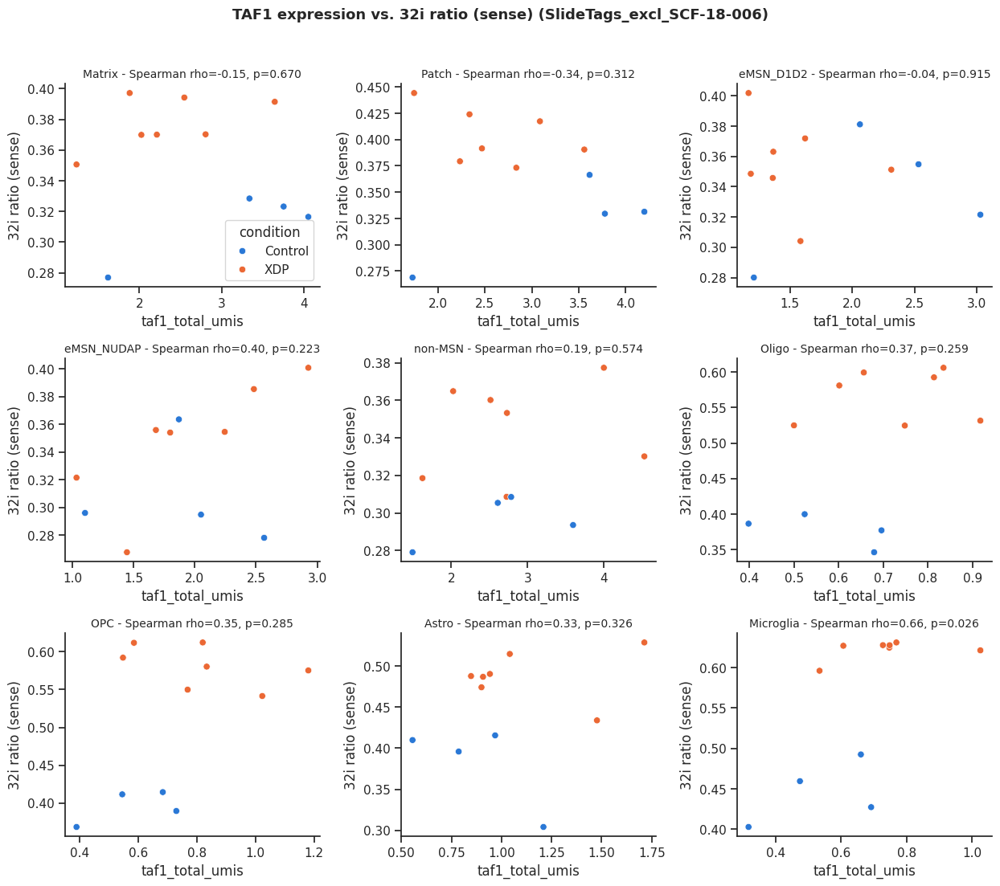


32i ratio (antisense)
Matrix: n=11, rho=-0.62, p=0.043
Patch: n=11, rho=-0.37, p=0.259
eMSN_D1D2: n=11, rho=-0.21, p=0.533
eMSN_NUDAP: n=11, rho=-0.21, p=0.537
non-MSN: n=11, rho=-0.45, p=0.160
Oligo: n=11, rho=0.20, p=0.555
OPC: n=11, rho=0.28, p=0.400
Astro: n=11, rho=-0.37, p=0.259
Microglia: n=11, rho=0.14, p=0.689


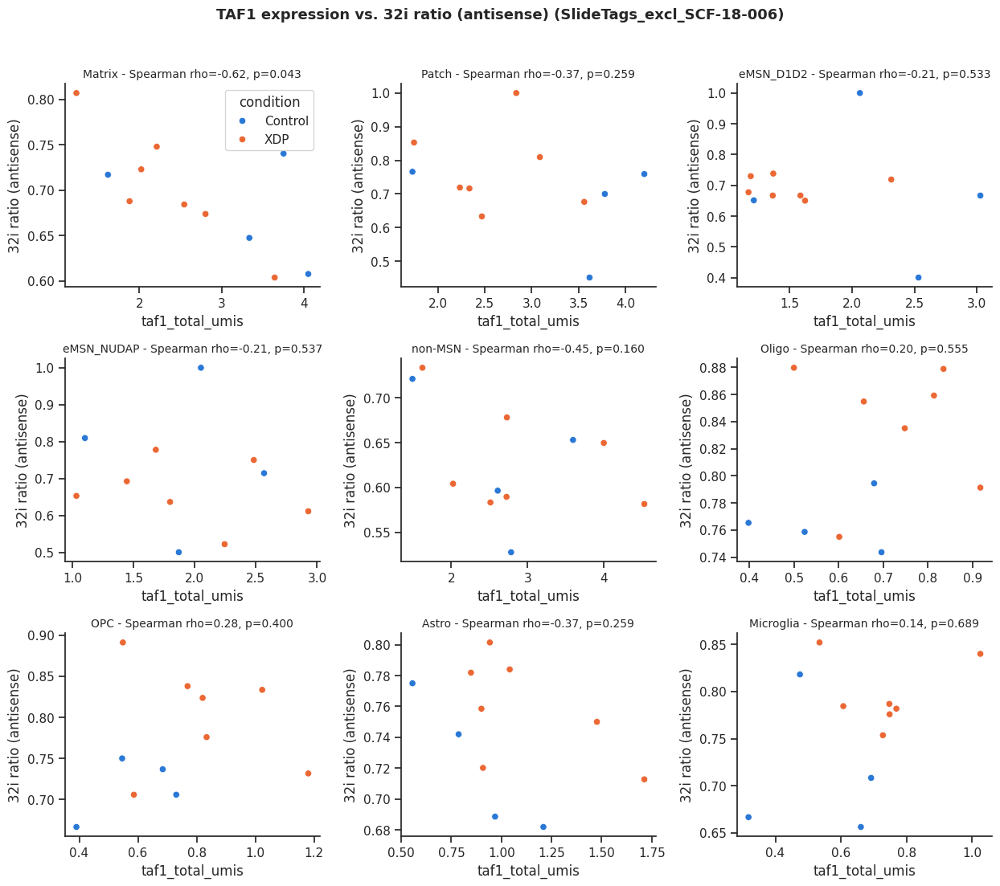

In [20]:
from scipy.stats import spearmanr

# checj if taf1 expression correlates with the pileup metric
cell_types = ["Matrix", "Patch", "eMSN_D1D2", "eMSN_NUDAP", "non-MSN", "Oligo", "OPC", "Astro", "Microglia"]

donor_taf1 = obs_st.groupby(["donor_id", "ct_for_deg"], observed=True)["taf1_total_umis"].mean().reset_index()
donor_taf1["ct_for_deg"] = donor_taf1["ct_for_deg"].astype(str)
df_taf1 = df_pseudobulk_all.merge(donor_taf1, on=["donor_id", "ct_for_deg"], how="left")
display(df_taf1[["donor_id", "ct_for_deg", "taf1_total_umis", *METRICS]].head())


def plot_taf1_correlation(df_taf1, metric, metric_label, cell_types, n_cols=3):
    # Spearman is rank based -> same rho/p as with the window-normalized version of the metric
    n_rows = -(-len(cell_types) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 3.6 * n_rows))
    axes = axes.flatten()
    for ax, ct in zip(axes, cell_types):
        sub = df_taf1.loc[df_taf1["ct_for_deg"] == ct, ["taf1_total_umis", metric, "condition", "donor_id"]].dropna()
        rho, pval = spearmanr(sub["taf1_total_umis"], sub[metric])
        sns.scatterplot(data=sub, x="taf1_total_umis", y=metric, hue="condition",
                        palette=CONDITION_COLORS, hue_order=["Control", "XDP"], ax=ax, legend=ax is axes[0])
        ax.set_title(f"{ct} - Spearman rho={rho:.2f}, p={pval:.3f}", fontsize=10)
        ax.set_ylabel(metric_label)
        sns.despine(ax=ax)
        print(f"{ct}: n={len(sub)}, rho={rho:.2f}, p={pval:.3f}")
    for ax in axes[len(cell_types):]:
        ax.set_visible(False)
    fig.suptitle(f"TAF1 expression vs. {metric_label} ({ANALYSIS_NAME})", fontsize=13, fontweight="bold", y=1.02)
    fig.tight_layout()
    plt.show()


for metric, metric_label in METRICS.items():
    print(f"\n{metric_label}\n{'=' * 60}")
    plot_taf1_correlation(df_taf1, metric, metric_label, cell_types)

# SlideTags only: 32i in dead vs healthy tissue region
`region` is defined only for cells with spatial position (`has_spatial`).
"dead" region is present only in XDP donors → paired test (Wilcoxon signed-rank) dead vs healthy within XDP donors; Control donors (healthy region) shown as reference.

,donor_id,condition,region,ct_for_deg,n_pre_umis,n_post_umis,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,n_cells,pileup_metric,pre_density,post_density,pileup_metric_norm,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction,post_antisense_fraction
0,SCF-18-003,XDP,dead,Astro,305.0,364.0,278.0,27.0,355.0,10.0,2598,0.455904,0.018743,0.030756,0.378649,0.439179,0.729730,0.088525,0.027397
1,SCF-18-003,XDP,dead,Matrix,365.0,566.0,299.0,67.0,551.0,15.0,1625,0.392052,0.022430,0.047824,0.319267,0.351765,0.817073,0.183060,0.026502
2,SCF-18-003,XDP,dead,Microglia,370.0,209.0,332.0,38.0,202.0,7.0,2341,0.639033,0.022737,0.017659,0.562847,0.621723,0.844444,0.102703,0.033493
3,SCF-18-003,XDP,dead,Oligo,2545.0,2069.0,2252.0,301.0,2035.0,35.0,17093,0.551582,0.156394,0.174820,0.472184,0.525309,0.895833,0.117901,0.016908
4,SCF-18-003,XDP,dead,Patch,108.0,123.0,98.0,10.0,120.0,3.0,346,0.467532,0.006637,0.010393,0.389718,0.449541,0.769231,0.092593,0.024390
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,SCF-23-075,Control,healthy,Microglia,64.0,74.0,59.0,5.0,73.0,1.0,1401,0.463768,0.003933,0.006253,0.386126,0.446970,0.833333,0.078125,0.013514
128,SCF-23-075,Control,healthy,Oligo,623.0,880.0,576.0,47.0,862.0,18.0,8387,0.414504,0.038284,0.074356,0.339882,0.400556,0.723077,0.075441,0.020455
129,SCF-23-075,Control,healthy,Patch,1112.0,2624.0,937.0,177.0,2568.0,57.0,5470,0.297645,0.068334,0.221715,0.235595,0.267332,0.756410,0.158887,0.021714
130,SCF-23-075,Control,healthy,eMSN_D1D2,232.0,559.0,207.0,25.0,544.0,15.0,1511,0.293300,0.014257,0.047233,0.231856,0.275632,0.625000,0.107759,0.026834



32i ratio (sense)
Matrix: n paired XDP donors=6, median(dead - healthy)=0.0548, Wilcoxon p=4.3750e-01
Patch: n paired XDP donors=7, median(dead - healthy)=0.0523, Wilcoxon p=7.8125e-02
eMSN_D1D2: n paired XDP donors=7, median(dead - healthy)=0.0429, Wilcoxon p=1.0938e-01
non-MSN: n paired XDP donors=7, median(dead - healthy)=0.0118, Wilcoxon p=7.8125e-02
Oligo: n paired XDP donors=7, median(dead - healthy)=0.0063, Wilcoxon p=3.7500e-01
Astro: n paired XDP donors=7, median(dead - healthy)=0.0153, Wilcoxon p=2.9688e-01
Microglia: n paired XDP donors=7, median(dead - healthy)=0.0106, Wilcoxon p=8.1250e-01


/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


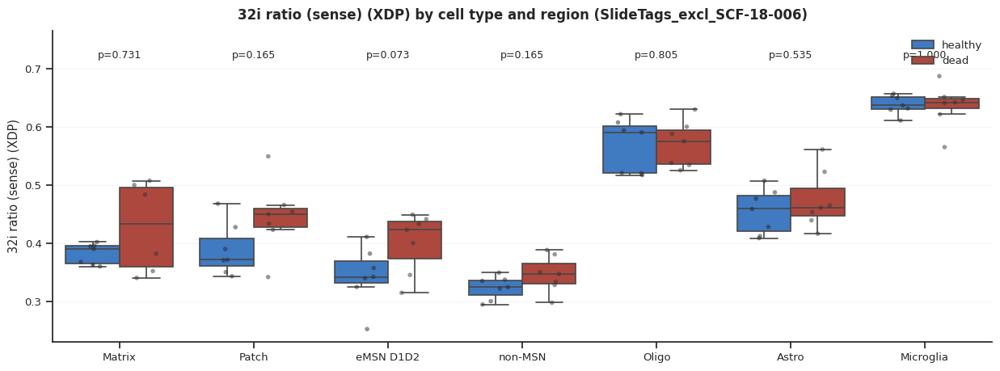

/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


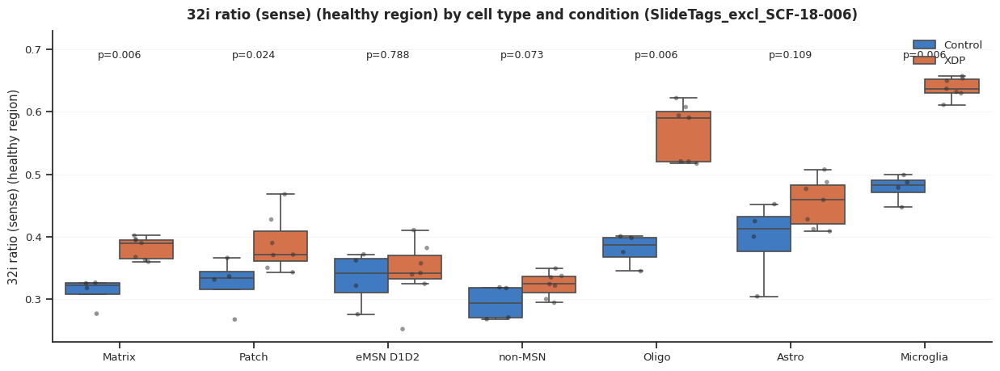


32i ratio (antisense)
Matrix: n paired XDP donors=6, median(dead - healthy)=0.0006, Wilcoxon p=8.4375e-01
Patch: n paired XDP donors=5, median(dead - healthy)=-0.0664, Wilcoxon p=8.1250e-01
eMSN_D1D2: n paired XDP donors=5, median(dead - healthy)=-0.1048, Wilcoxon p=4.3750e-01
non-MSN: n paired XDP donors=7, median(dead - healthy)=0.0377, Wilcoxon p=9.3750e-01
Oligo: n paired XDP donors=7, median(dead - healthy)=0.0226, Wilcoxon p=9.3750e-01
Astro: n paired XDP donors=7, median(dead - healthy)=-0.0040, Wilcoxon p=6.8750e-01
Microglia: n paired XDP donors=7, median(dead - healthy)=-0.0841, Wilcoxon p=3.7500e-01


/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


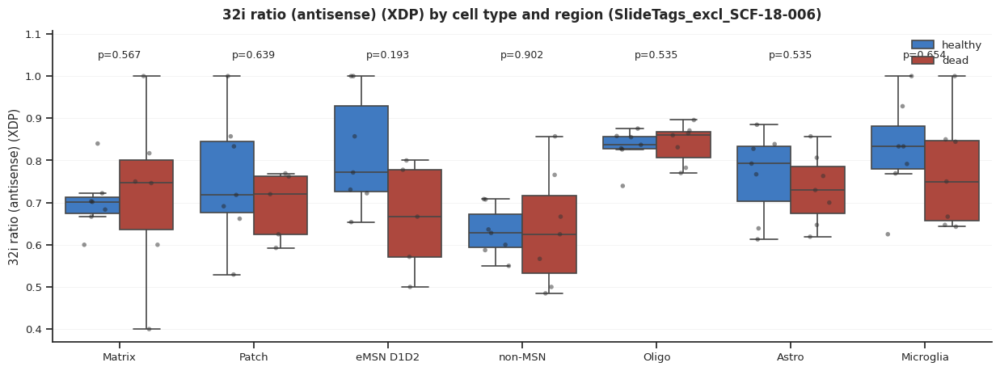

/tmp/ipykernel_9449/58131920.py:22: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=data, x="ct_for_deg", y=y, hue=hue, order=order,
/tmp/ipykernel_9449/58131920.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([lbl.get_text().replace("_", " ") for lbl in ax.get_xticklabels()])


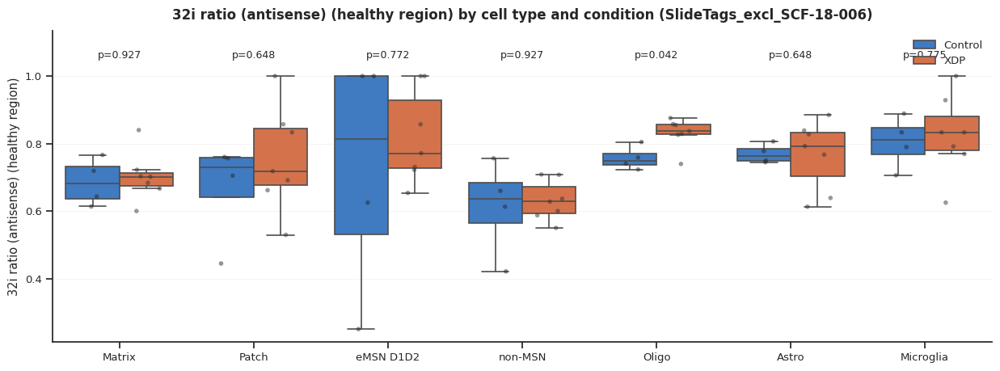

In [21]:
from scipy.stats import wilcoxon

REGION_COLORS = {"healthy": "#2a78d6", "dead": "#c0392b"}
cell_types = ["Matrix", "Patch", "eMSN_D1D2", "non-MSN", "Oligo", "Astro", "Microglia"]

tmp = obs_st_an[obs_st_an["region"].notna() & obs_st_an["ct_for_deg"].isin(cell_types)].copy()
tmp["region"] = tmp["region"].astype(str)
df_pseudobulk_region = pseudobulk_32i(tmp, ["donor_id", "condition", "region", "ct_for_deg"])
df_pseudobulk_region["ct_for_deg"] = df_pseudobulk_region["ct_for_deg"].astype(str)

# drop donor-ct-region groups with too few cells (e.g. 1 "dead" cell in a control)
MIN_CELLS = 20
df_pseudobulk_region = df_pseudobulk_region[df_pseudobulk_region["n_cells"] >= MIN_CELLS]
df_pseudobulk_region.to_csv(OUT_DIR / f"32i_per_donor_region_{ANALYSIS_NAME}.csv", index=False)
display(df_pseudobulk_region)


def analyze_region(df_region, metric, metric_label, cell_types):

    # paired dead vs healthy, XDP donors only
    df_xdp_region = df_region[df_region["condition"] == "XDP"]
    for ct in cell_types:
        paired = (
            df_xdp_region[df_xdp_region["ct_for_deg"] == ct]
            .pivot(index="donor_id", columns="region", values=metric)
            .dropna()
        )
        if len(paired) < 3 or not {"dead", "healthy"} <= set(paired.columns):
            print(f"{ct}: skipped (n paired donors={len(paired)})")
            continue
        _, pval = wilcoxon(paired["dead"], paired["healthy"])
        print(f"{ct}: n paired XDP donors={len(paired)}, median(dead - healthy)={(paired['dead'] - paired['healthy']).median():.4f}, Wilcoxon p={pval:.4e}")

    # XDP: dead vs healthy (p-values in plot are unpaired Mann-Whitney, see paired test above)
    plot_pileup(df_xdp_region, metric, cell_types, ylabel=f"{metric_label} (XDP)",
                hue="region", hue_order=("healthy", "dead"), palette=REGION_COLORS)

    # healthy region only: Control vs XDP (removes the dead tissue effect)
    plot_pileup(df_region[df_region["region"] == "healthy"], metric, cell_types,
                ylabel=f"{metric_label} (healthy region)")


for metric, metric_label in METRICS.items():
    print(f"\n{metric_label}\n{'=' * 60}")
    analyze_region(df_pseudobulk_region, metric, metric_label, cell_types)

# Spatial position

In [22]:
import scanpy as sc
import pandas as pd
import numpy as np
from pathlib import Path

ADATA_PATH = "/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/all_lib_adata_zoned_ct-cured_aligned.h5ad"
OUT_DIR    = Path("/home/gdallagl/myworkdir/XDP/data/XDP/SlideTags_dataset/32i")
DATASET    = "SlideTags"

# full load in memory (~40 GB RAM; X is empty, raw counts are in layers["counts"])
adata = sc.read_h5ad(ADATA_PATH)

# per-cell 32i metrics computed above
METRIC_COLS = [
    "n_pre_umis", "n_post_umis", "pileup_metric", "pre_density", "post_density", "pileup_metric_norm",
    "n_pre_sense_umis", "n_pre_antisense_umis", "n_post_sense_umis", "n_post_antisense_umis",
    "pileup_metric_sense", "pileup_metric_antisense", "pre_antisense_fraction",
]
df_32i = pd.read_csv(
    OUT_DIR / f"32i_per_cell_{DATASET}.csv",
    usecols=["library_id", "original_barcode", *METRIC_COLS],
    dtype={"library_id": str, "original_barcode": str},
).set_index(["library_id", "original_barcode"])

# attach to each cell, matching on library + barcode (keeps adata order)
# cells removed as low quality ("-Low_quality", "-TAFA1", "tmp") were not quantified -> NaN
key = pd.MultiIndex.from_arrays([adata.obs["library_id"].astype(str), adata.obs["original_barcode"].astype(str)])
adata.obs[METRIC_COLS] = df_32i.reindex(key)[METRIC_COLS].to_numpy()

# TAF1 raw UMIs per cell
taf1_col = np.flatnonzero(adata.var["gene_symbol"] == "TAF1")[0]
adata.obs["taf1_total_umis"] = np.asarray(adata.layers["counts"][:, taf1_col].todense()).ravel()

print(f"cells with 32i metrics: {adata.obs['n_pre_umis'].notna().sum()} / {adata.n_obs}")
adata.obs[["donor_id", "condition", "ct_for_deg", "taf1_total_umis", *METRIC_COLS]].head()

cells with 32i metrics: 742896 / 742896


,donor_id,condition,ct_for_deg,taf1_total_umis,n_pre_umis,n_post_umis,pileup_metric,pre_density,post_density,pileup_metric_norm,n_pre_sense_umis,n_pre_antisense_umis,n_post_sense_umis,n_post_antisense_umis,pileup_metric_sense,pileup_metric_antisense,pre_antisense_fraction
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGATAACAG-1,SCF-18-003,diseased,Astro,0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGCATGGAG-1,SCF-18-003,diseased,Microglia,0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGCGGAGT-1,SCF-18-003,diseased,Oligo,0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTCTATG-1,SCF-18-003,diseased,Astro,0,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN
251027_SL-EXD_0706_A233KGFLT4---SI-TT-H1---AAACCAAAGGTTGTAT-1,SCF-18-003,diseased,Oligo,1,0.0,0.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,0.0,NaN,NaN,NaN


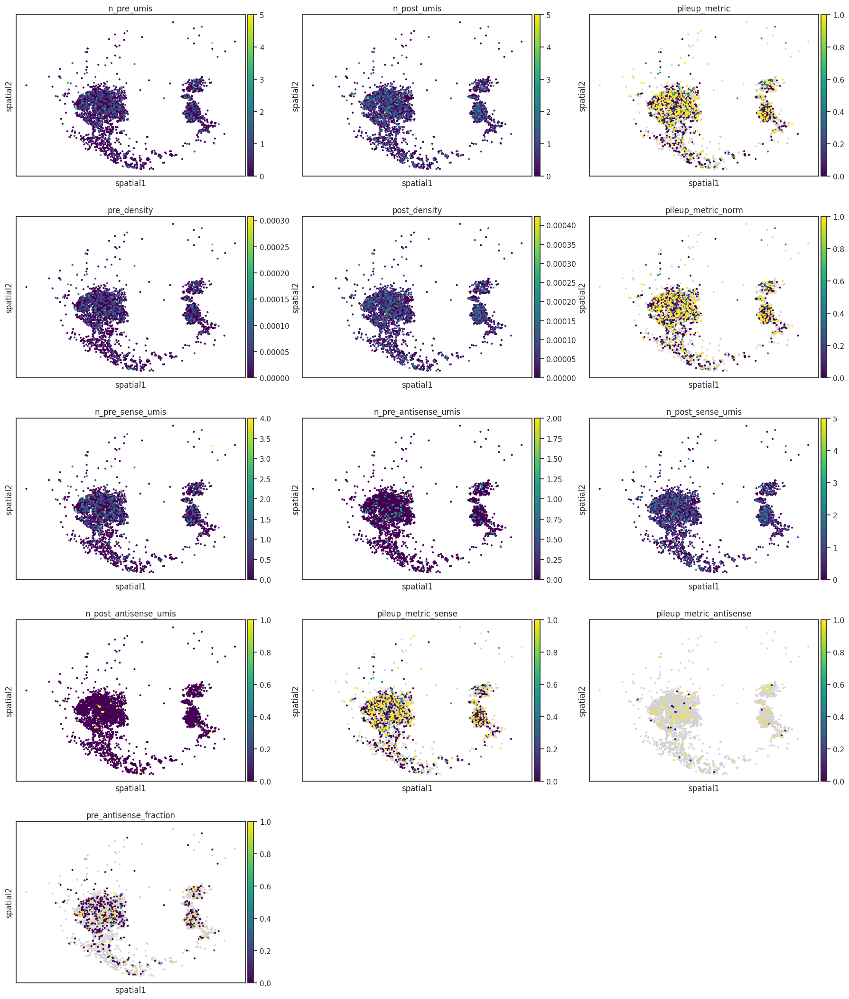

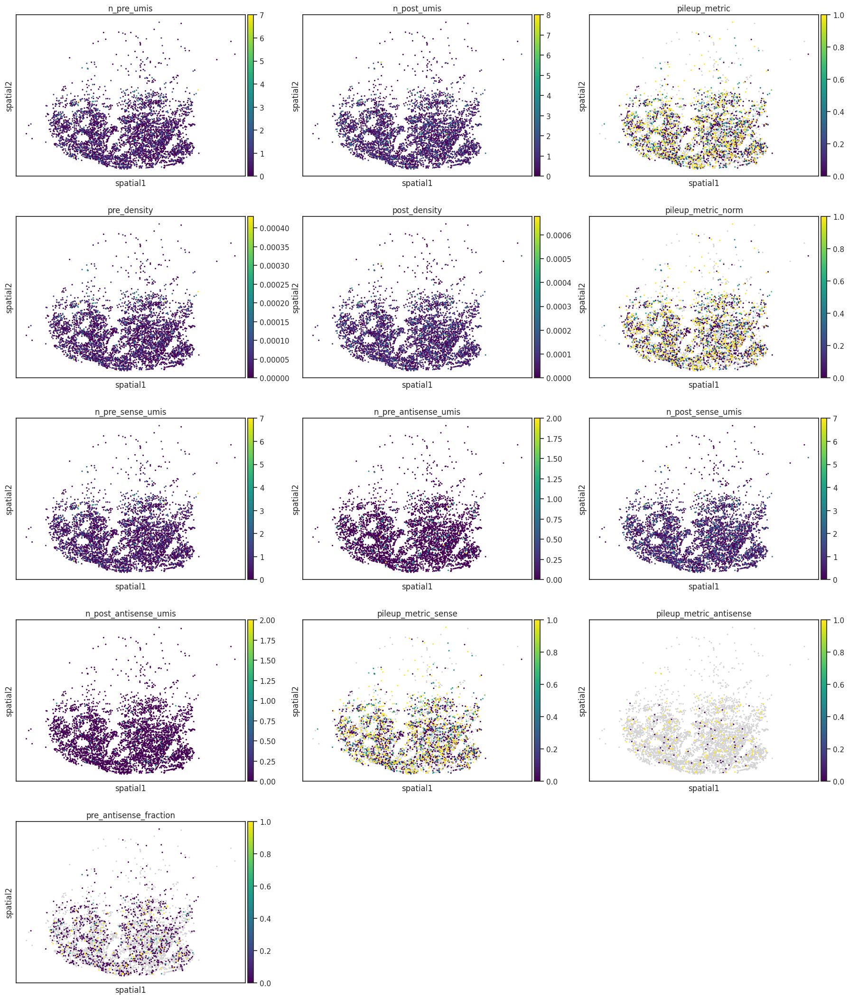

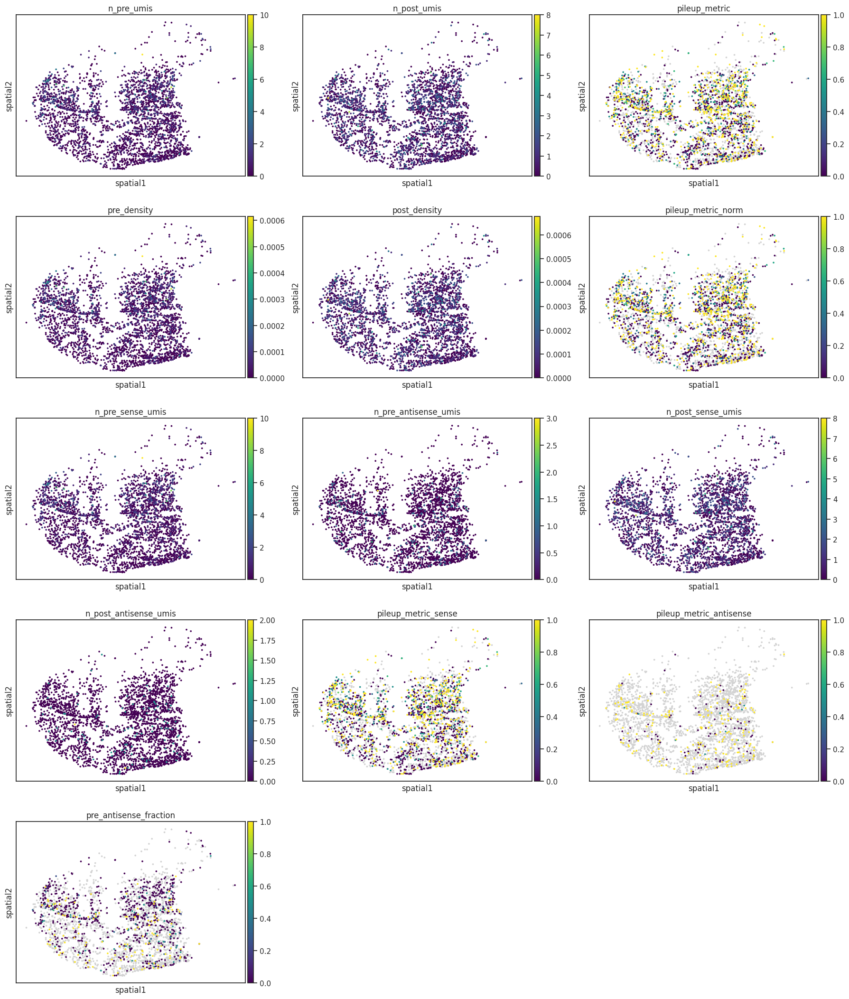

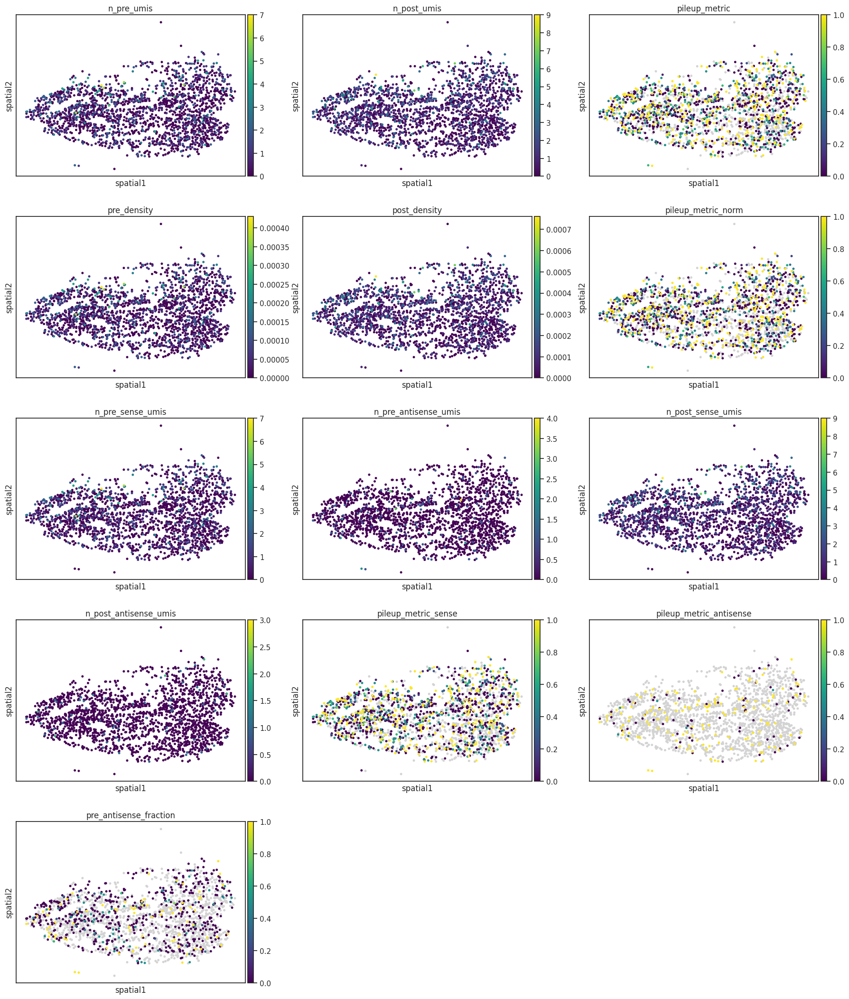

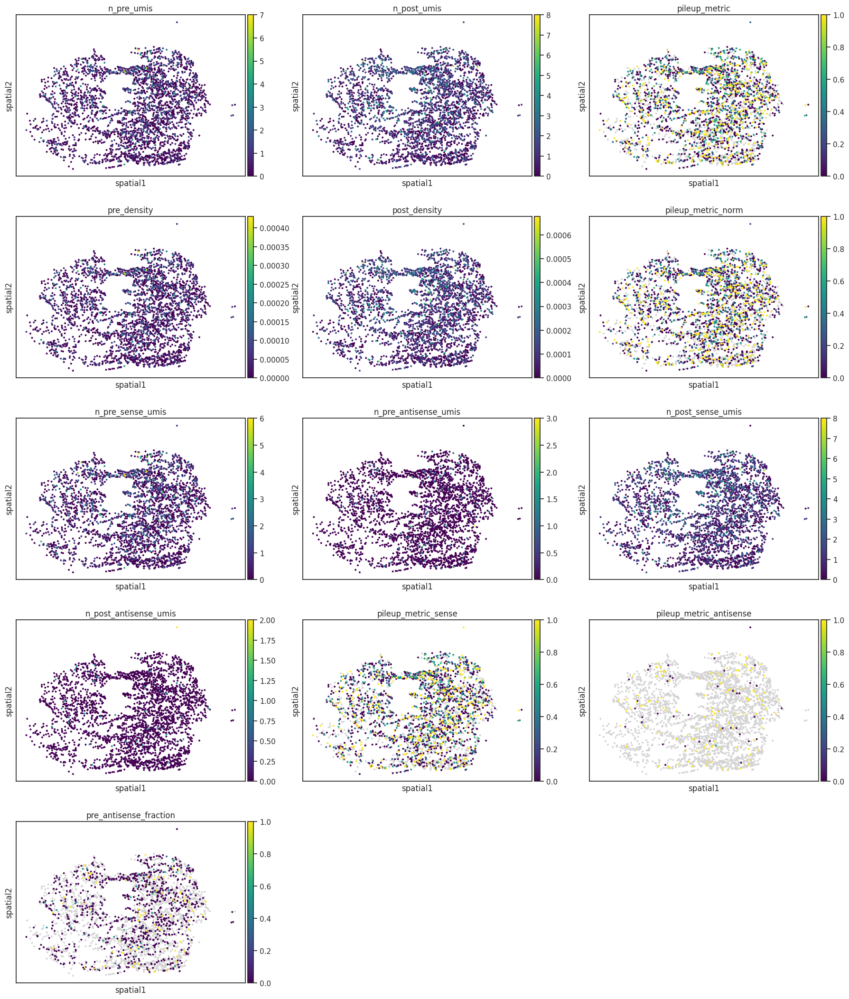

...

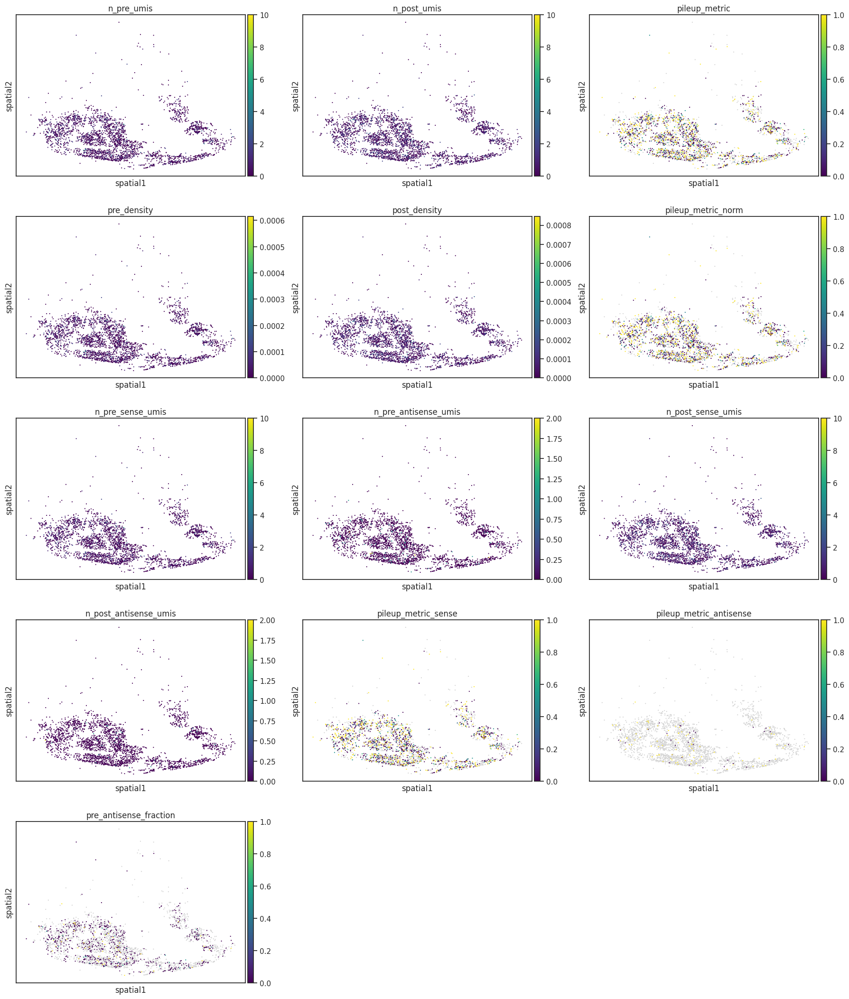

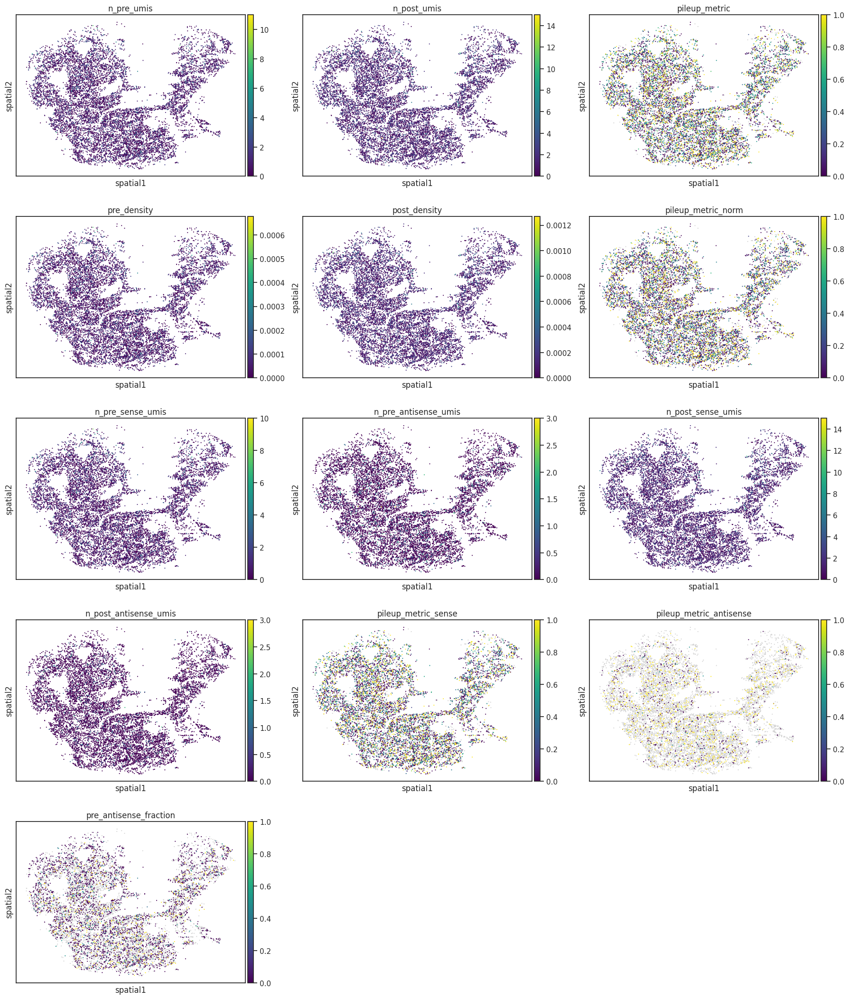

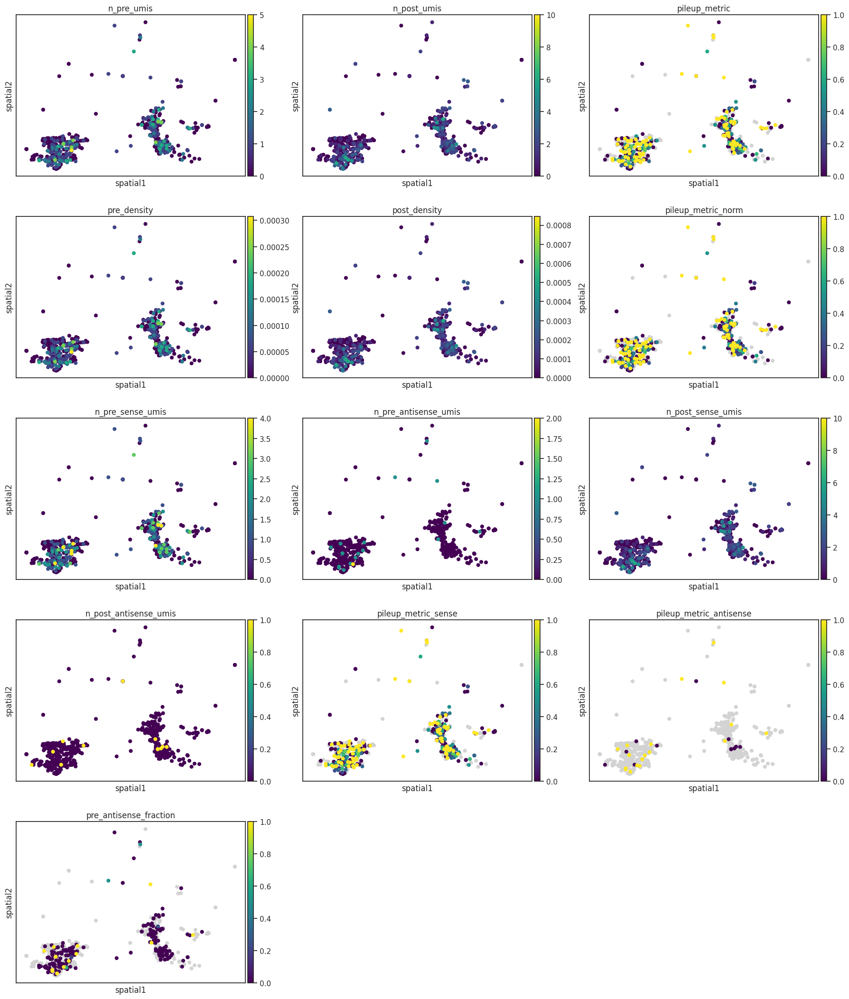

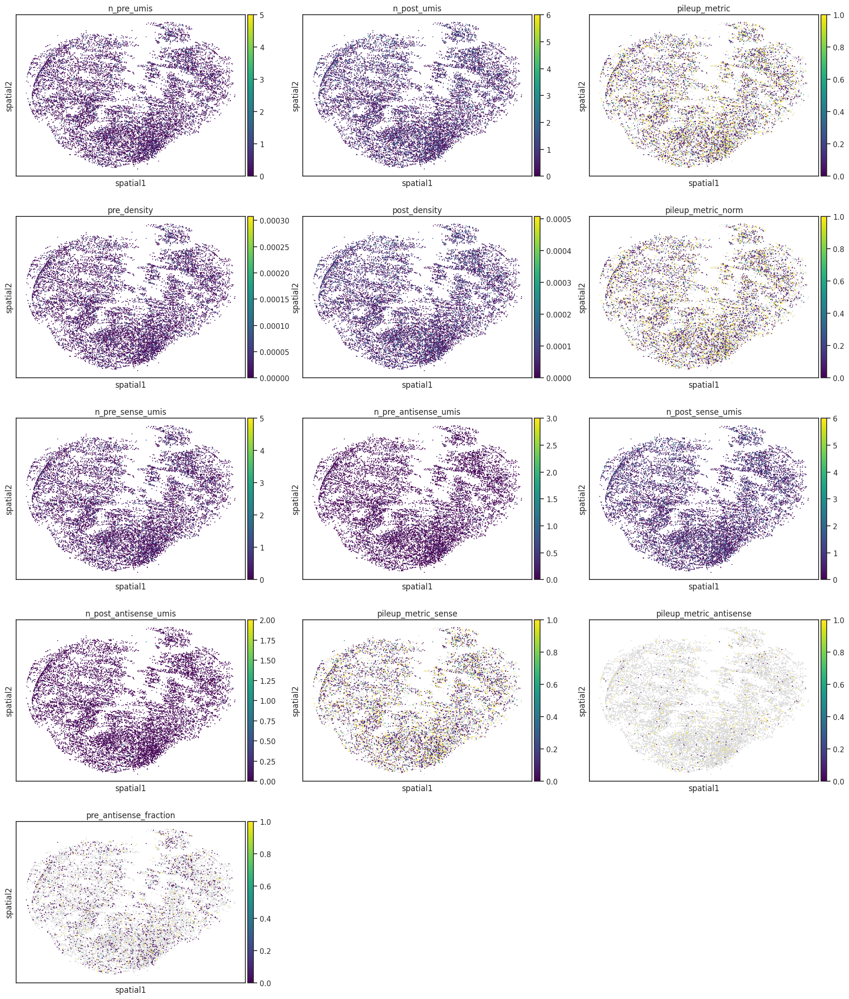

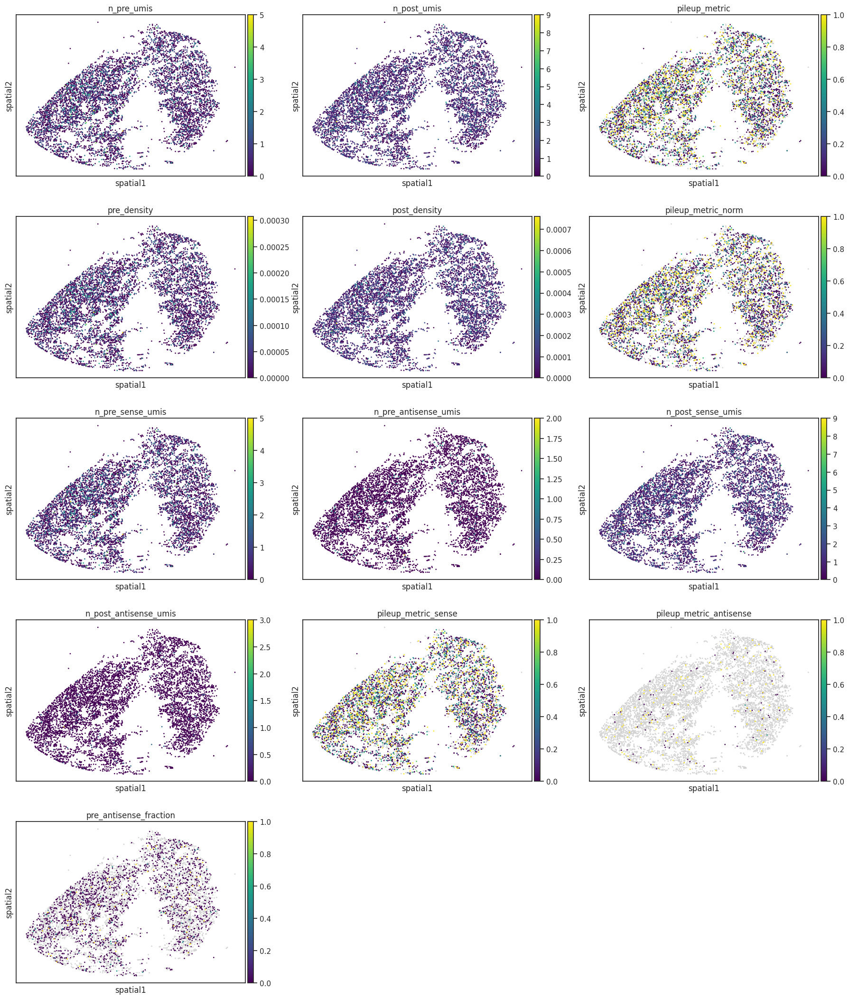

In [ ]:
for sample in adata.obs["sample"].unique():

    sc.pl.embedding(
        adata[
            (adata.obs["sample"] == sample) &
            (adata.obs["ct_for_deg"].isin(["Matrix_D1", "Matrix_D2"])),  # Example additional condition
            ], basis="spatial", ncols=3, cmap="viridis",
            color=[
    "n_pre_umis", "n_post_umis", "pileup_metric", 
    "pre_density", "post_density", "pileup_metric_norm",
    "n_pre_sense_umis", "n_pre_antisense_umis", 
    "n_post_sense_umis", "n_post_antisense_umis",
    "pileup_metric_sense", "pileup_metric_antisense", 
    "pre_antisense_fraction",
        ])

    #break

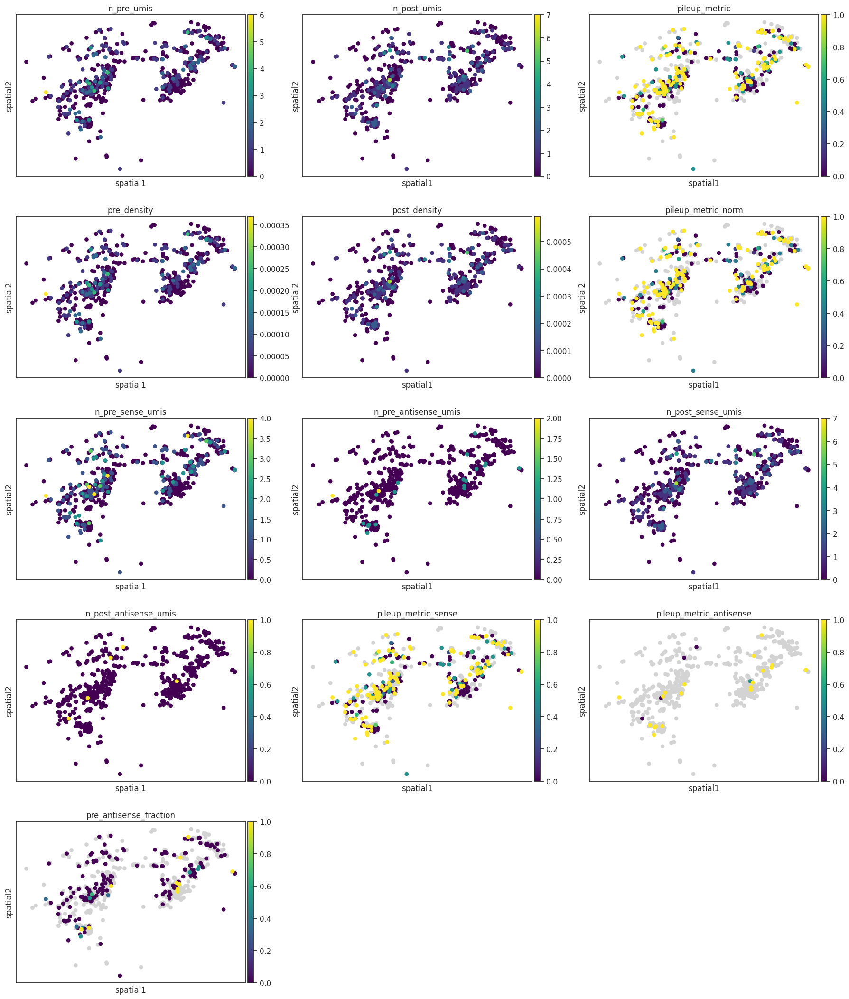

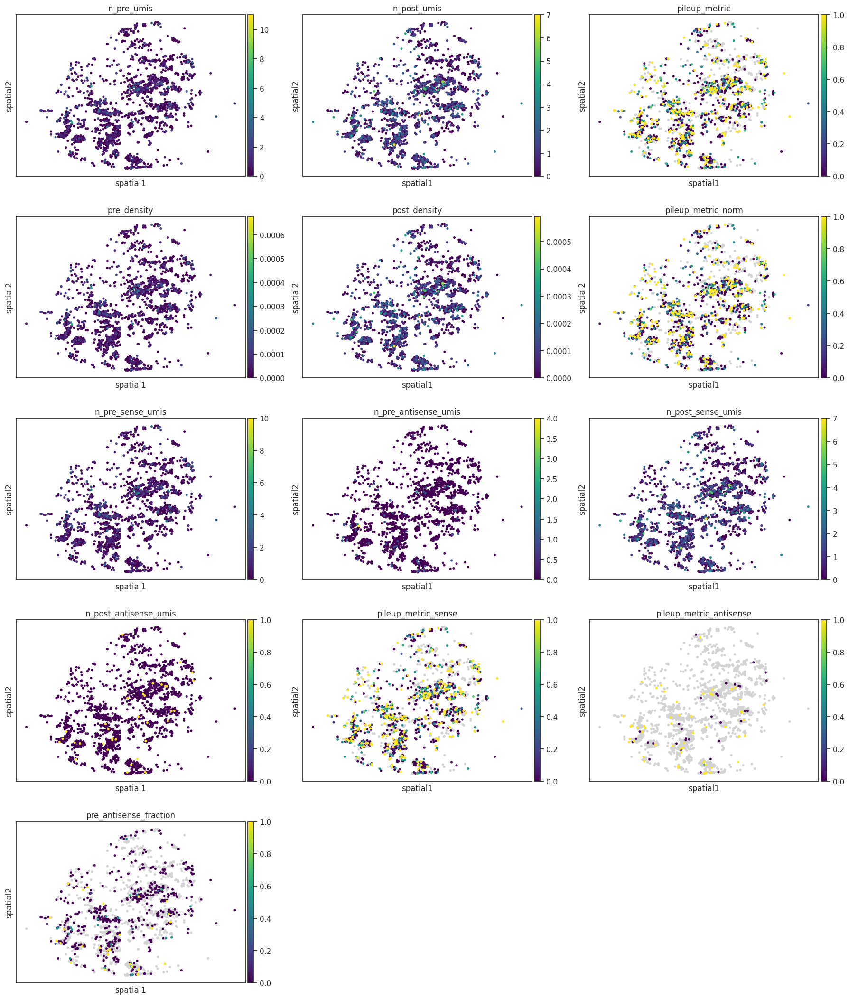

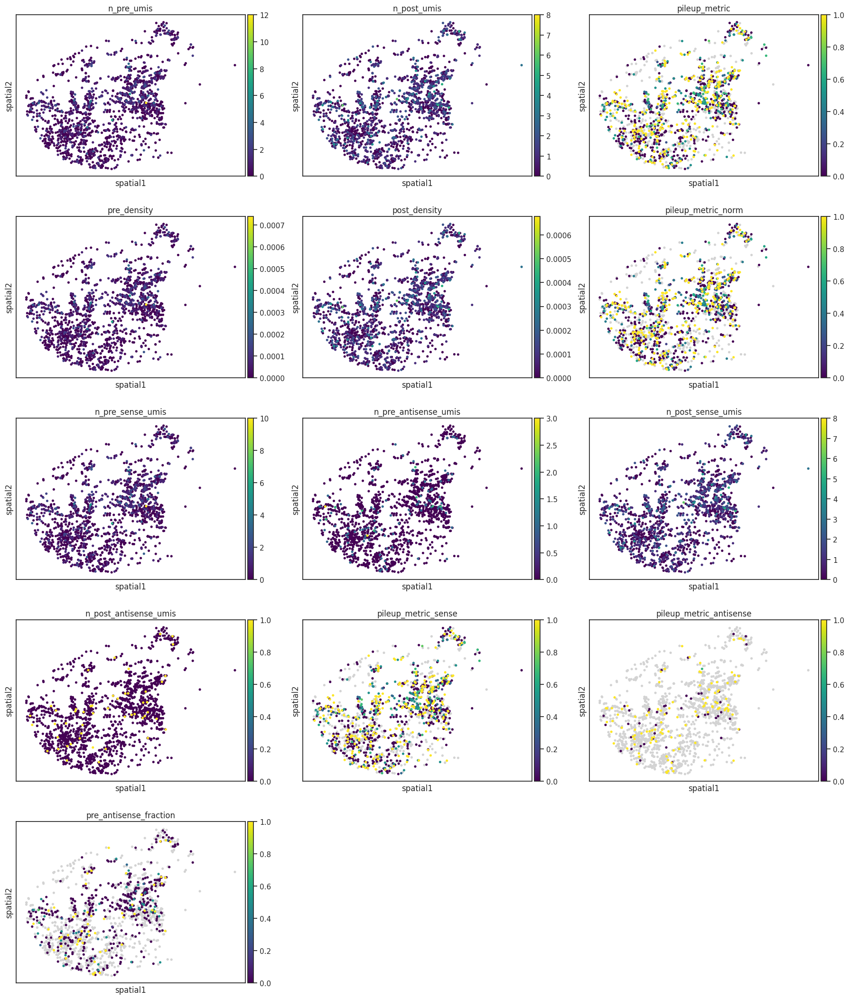

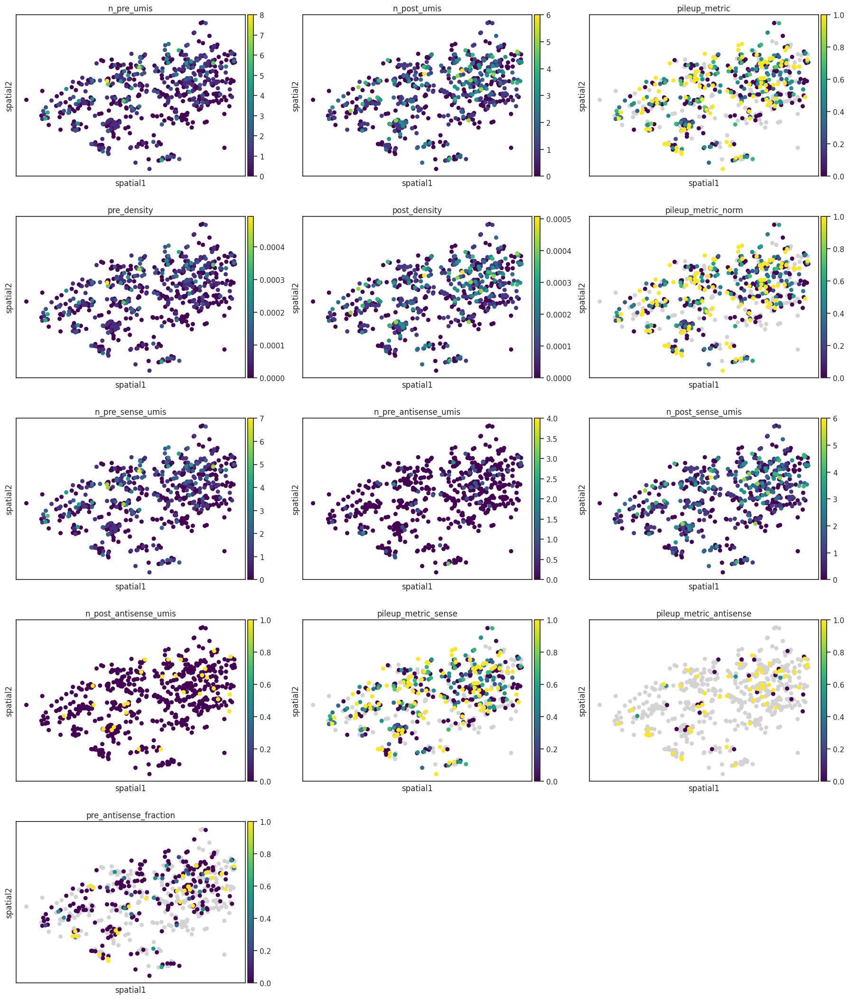

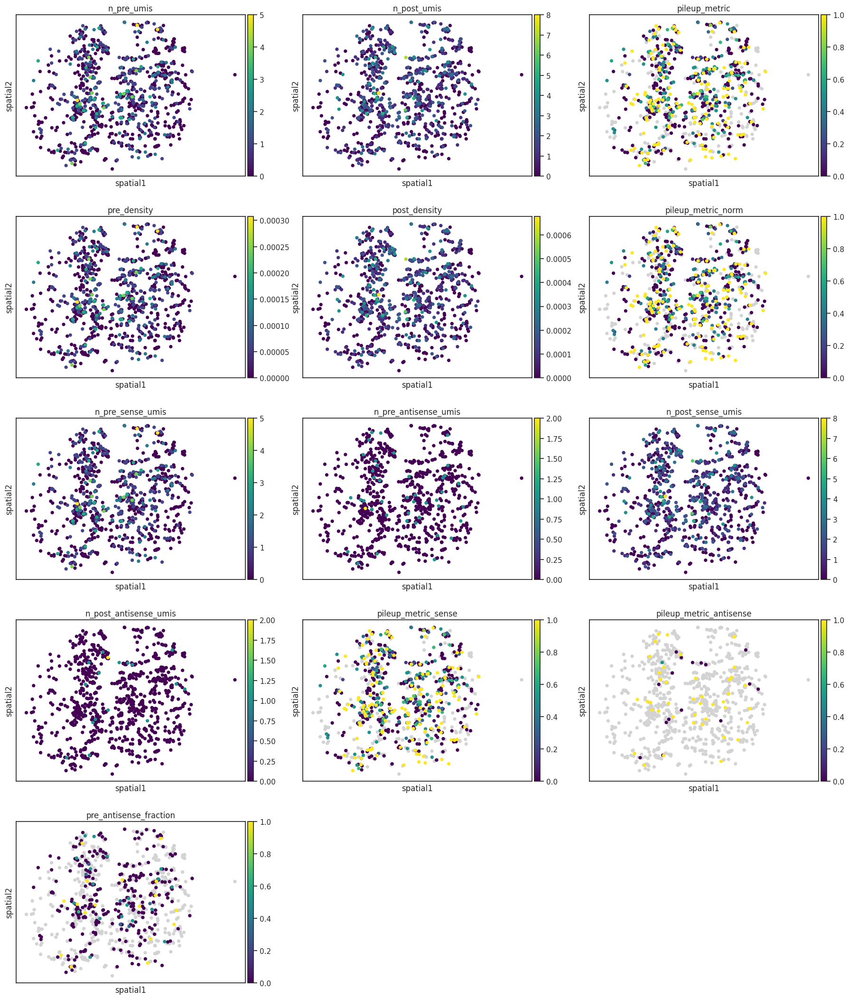

...

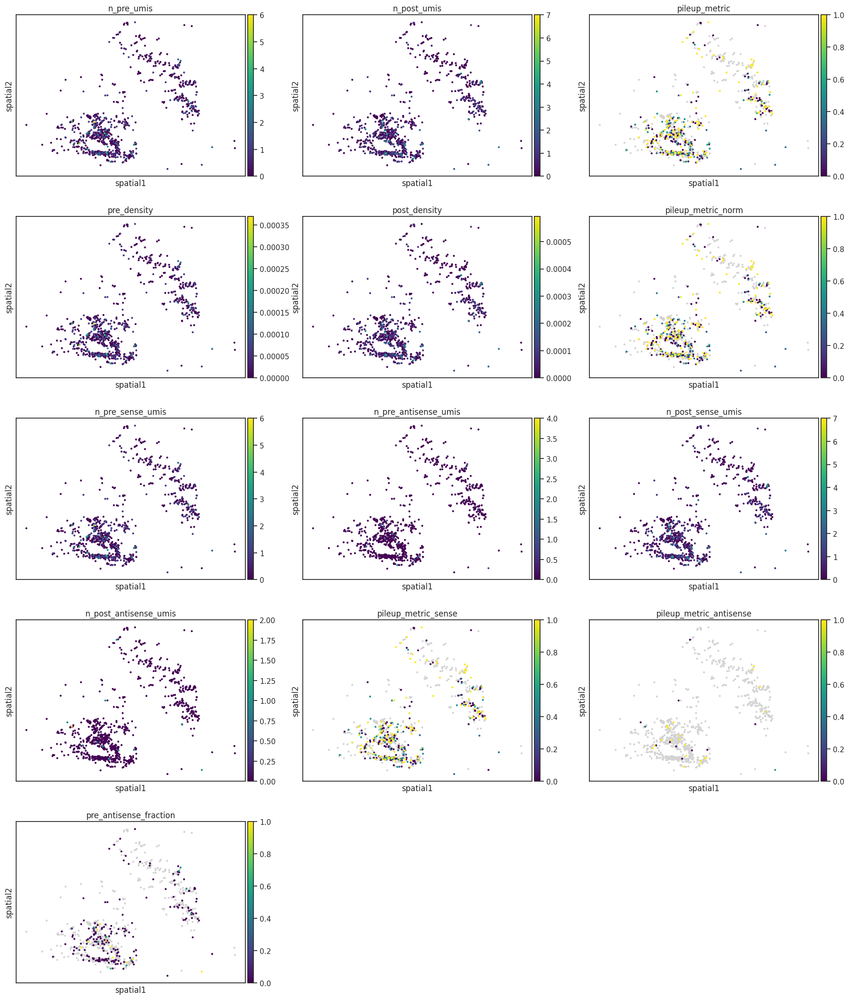

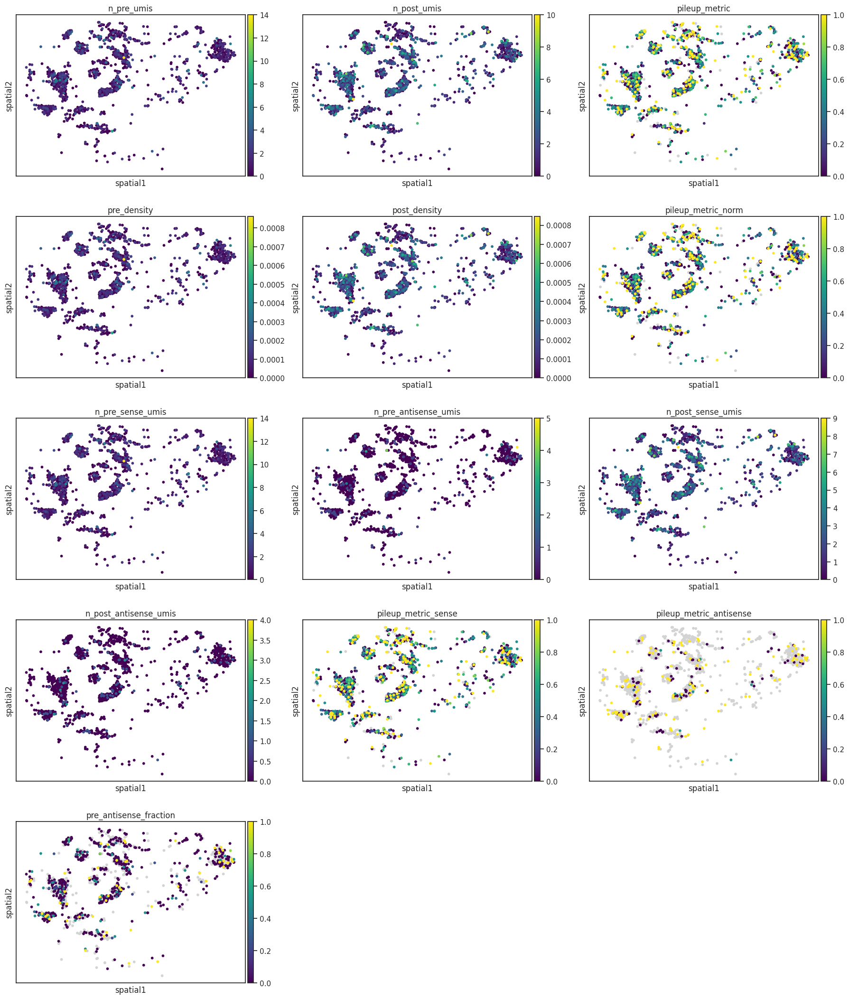

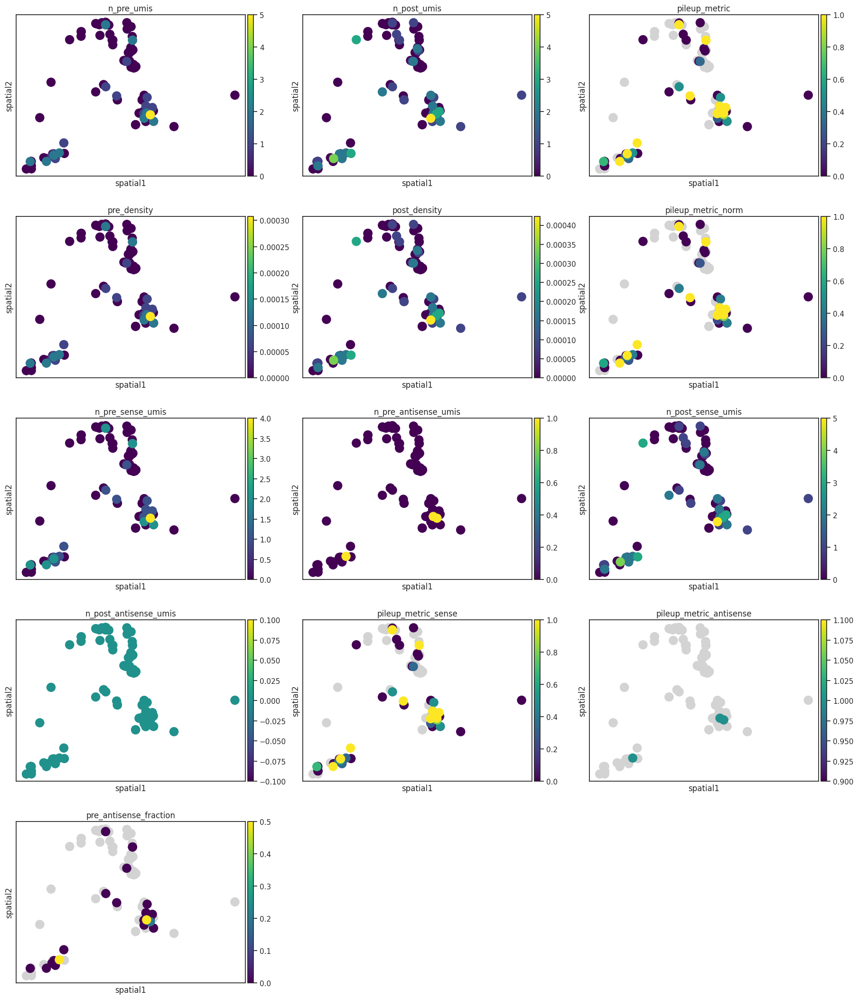

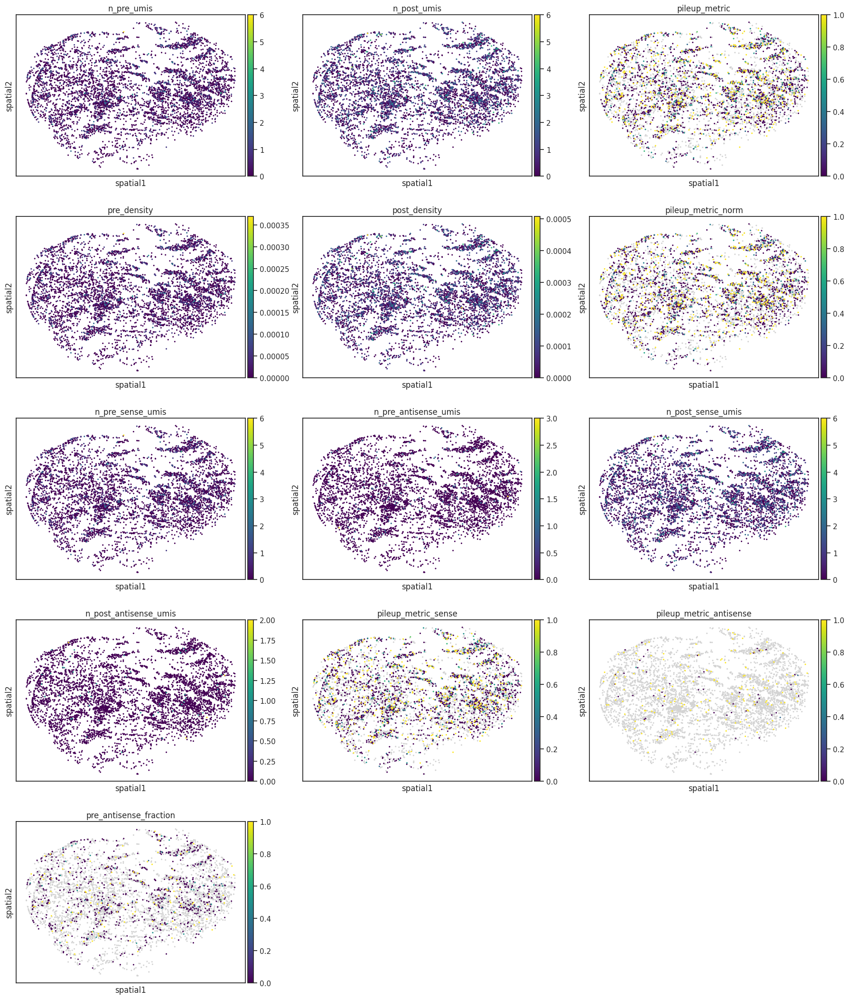

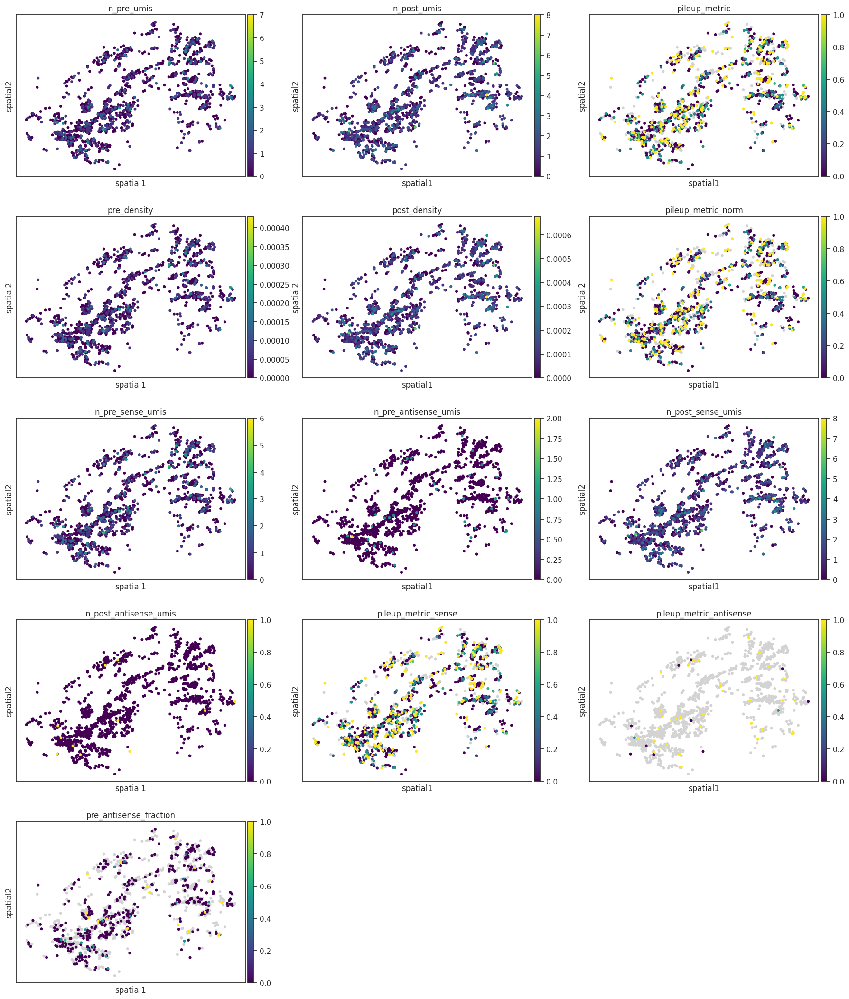

In [24]:

for sample in adata.obs["sample"].unique():

    sc.pl.embedding(
        adata[
            (adata.obs["sample"] == sample) &
            (adata.obs["ct_for_deg"].isin(["Patch_D1", "Patch_D2"])),  # Example additional condition
            ], basis="spatial", ncols=3, cmap="viridis",
            color=[
    "n_pre_umis", "n_post_umis", "pileup_metric", 
    "pre_density", "post_density", "pileup_metric_norm",
    "n_pre_sense_umis", "n_pre_antisense_umis", 
    "n_post_sense_umis", "n_post_antisense_umis",
    "pileup_metric_sense", "pileup_metric_antisense", 
    "pre_antisense_fraction",
        ])

    #break